# OPM-MEG FIF to BIDS

**Pygers-MEG** · step-by-step conversion of one task recording and its empty-room
recording (both already converted to `.fif` by cMEG2FIF) into a valid BIDS dataset.

**Environment:** the `pygers-meg` conda env (mne, mne-bids, jupyterlab, pandas, ipykernel, ipympl).

## What this notebook produces

```
<BIDS_ROOT>/
├── dataset_description.json      ← dataset level (Section 10)
├── README
├── CHANGES
├── LICENSE
├── CITATION.cff
├── participants.tsv / .json
├── task-<label>_meg.json         ← task-level sidecar
└── sub-<label>/ses-<label>/
    ├── sub-…_scans.tsv
    ├── anat/                       ← T1w/T2w from notebook 03 (Section 12)
    ├── beh/                        ← PsychoPy behavioral logs (Section 13)
    └── meg/
        ├── sub-…_coordsystem.json
        ├── sub-…_task-<label>_run-<n>_meg.fif / .json / _channels.tsv / _channels.json
        ├── sub-…_task-<label>_run-<n>_events.tsv / _events.json
        └── sub-…_task-noise_meg.fif / .json / _channels.tsv / _channels.json   ← empty room
```

## Why the sections are in this order

`mne_bids.write_raw_bids()` writes every file in the tree, but fills many fields with placeholders,
defaults meant for other MEG systems, or nothing at all. It also **regenerates or appends to**
`dataset_description.json`, `README` and `participants.tsv/.json` each time it is called. So:

1. **Sections 0-2** - Set imports (0), paths (1), and helper functions (2).
2. **Sections 3–9**-  Load the FIF files (3), decode the events (4),
   create the BIDS tree (5), mark bad channels (6), set up anonymization (7), write the empty-room
   recording (8), then write the task recording linked to its empty-room (9).
3. **Section 10**-  fix the recording-level outputs (`_meg.json`, `_channels.tsv`, and the rest).
4. **Section 11**-  fix the dataset-level outputs (after the last `write_raw_bids()` call so that
   nothing overwrites them).
5. **Section 12**-  add the MRI anatomicals converted in notebook 03 (`anat/`, with their dates in
   `scans.tsv` anonymized like the MEG's).
6. **Section 13**-  add the PsychoPy behavioral logs (`beh/`).
7. **Section 14**-  verify the result. (The whole dataset is validated with the BIDS validator in
   notebook 06, once notebook 05 has added the eye-tracking data.)

Within Sections 10 and 11, fields are fixed in the order of the flowchart's highlights:

🔴 **red** (BIDS REQUIRED, and MNE-BIDS writes a placeholder or a wrong value: you must set them).

🟡 **yellow** (BIDS RECOMMENDED/OPTIONAL, and wrong or empty: you should correct or fill them).

Requirement levels are from the [BIDS schema v1.11.2, MEG section](https://bids-specification.readthedocs.io/en/stable/modality-specific-files/magnetoencephalography.html#magnetoencephalography).

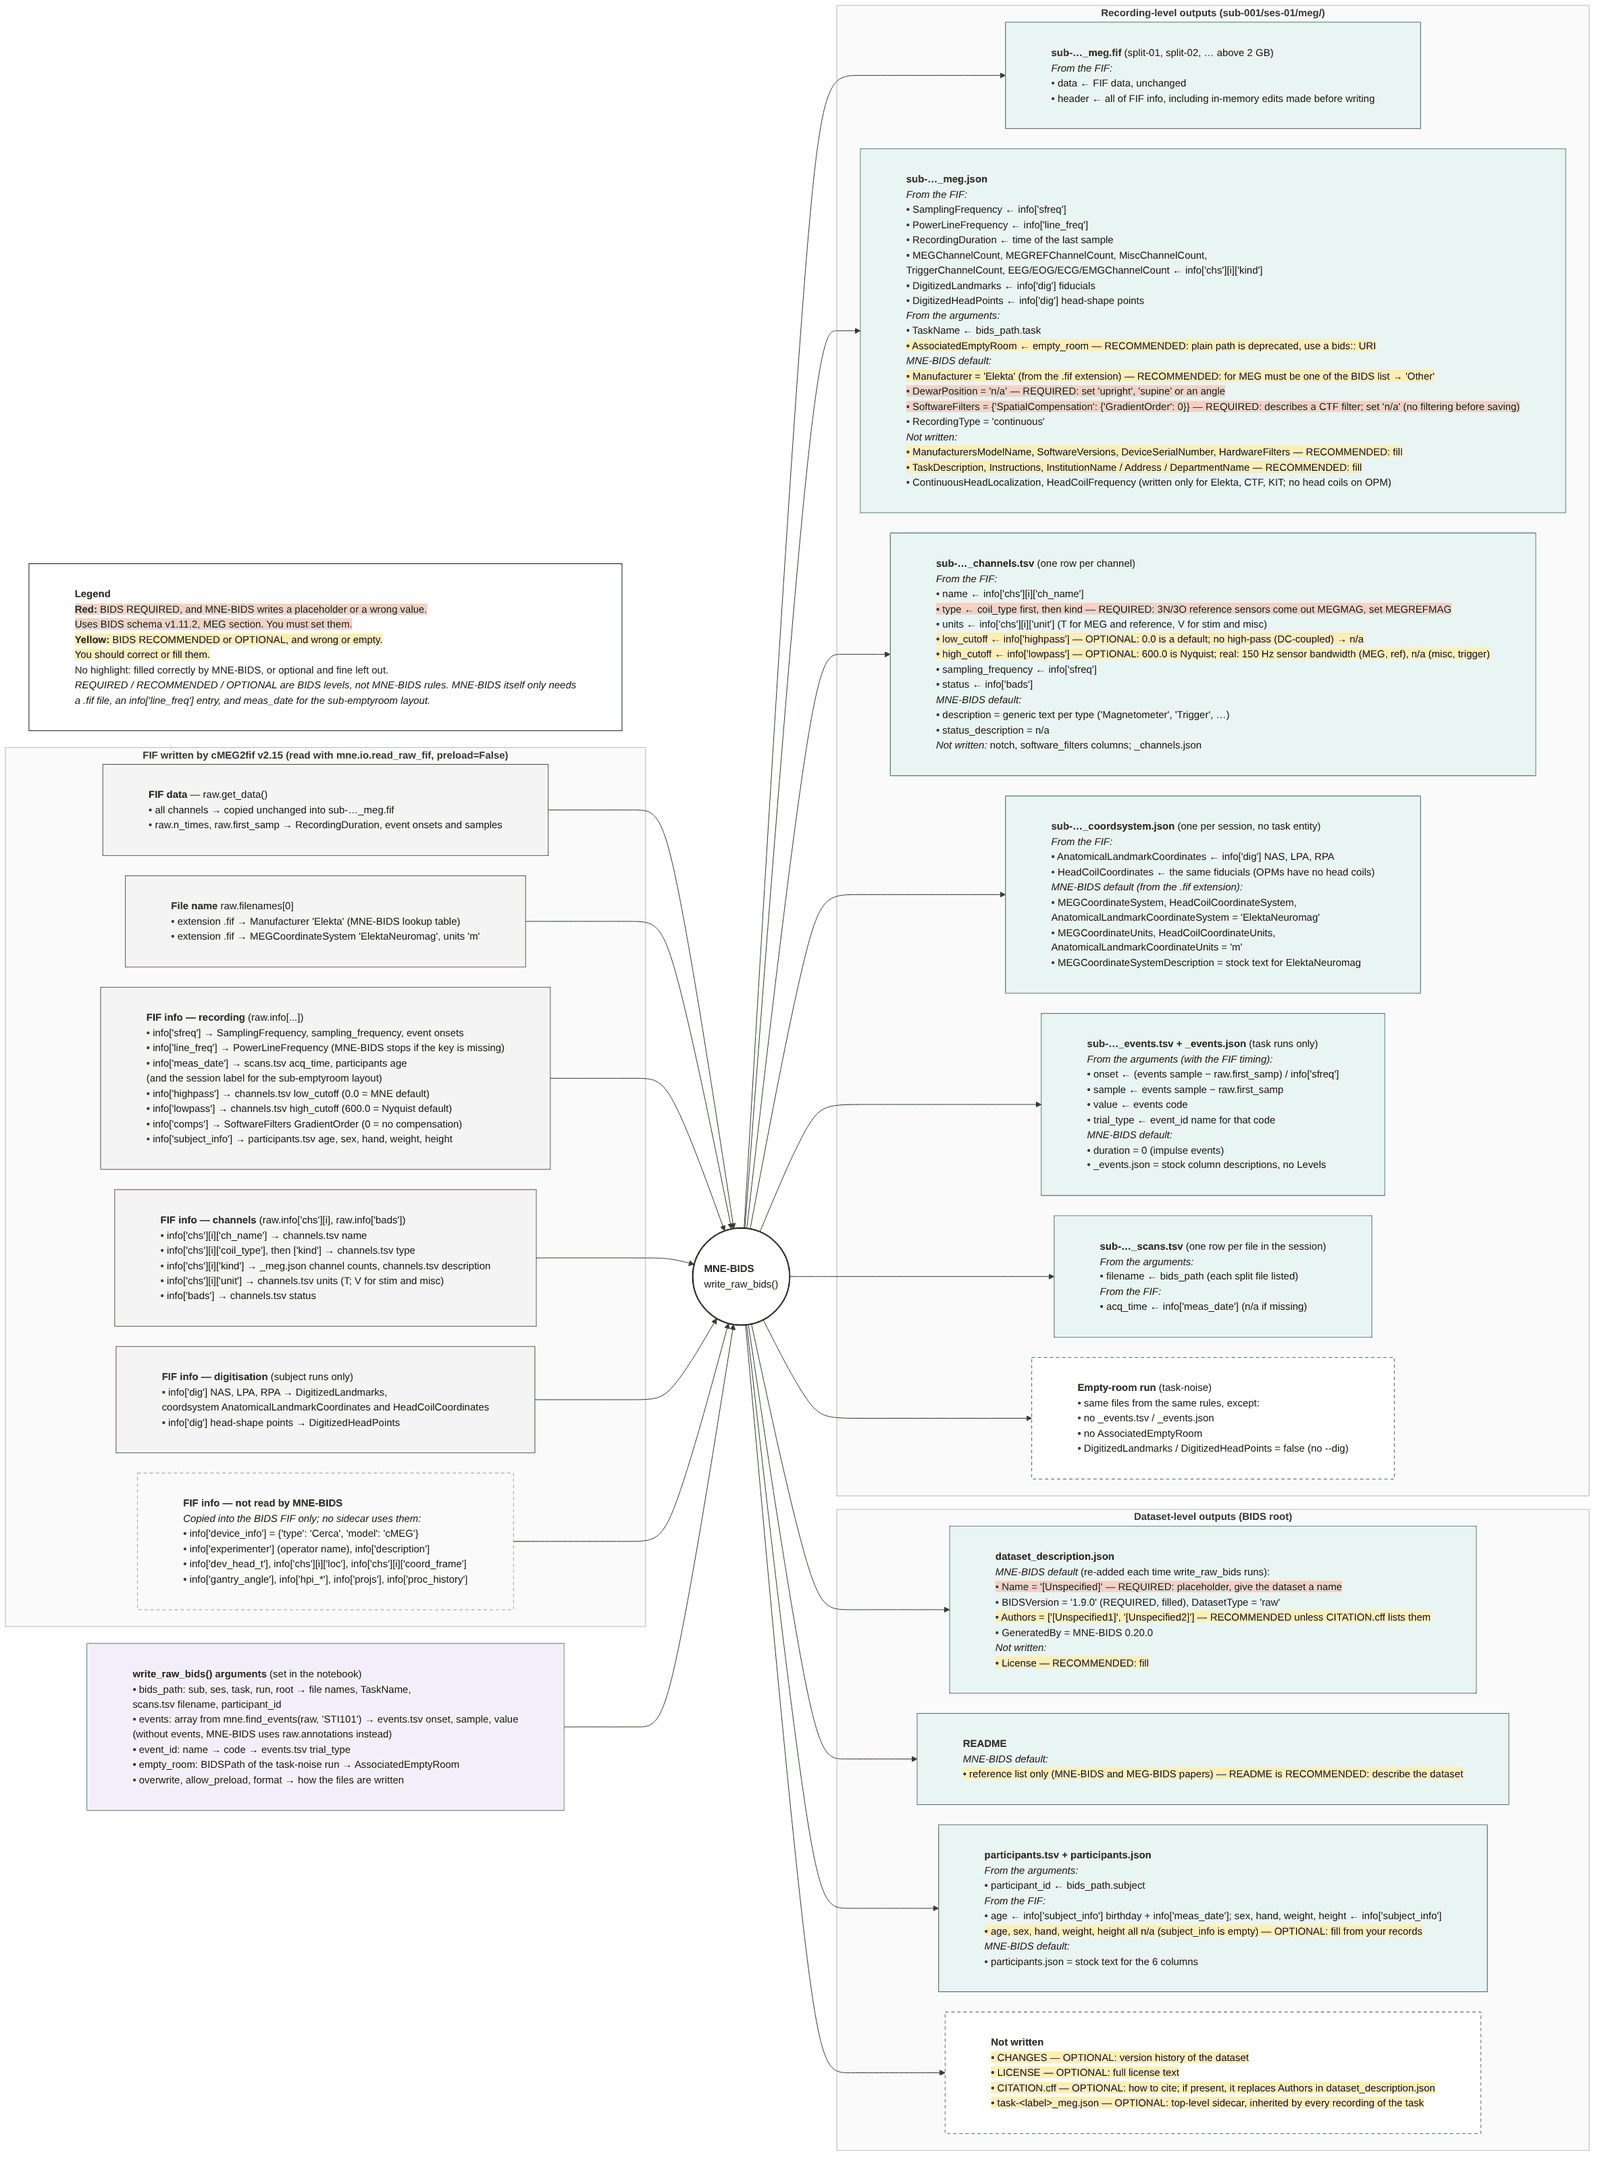

*The flowchart is embedded in this cell, so it shows wherever the notebook is opened. Full-resolution version: [docs/MNE-BIDS_outputs.svg](https://github.com/mrribbits/pygers-meg/blob/main/docs/MNE-BIDS_outputs.svg) (Mermaid source `docs/MNE-BIDS_outputs.mmd` alongside).*

> **How to use:** every cell that needs your input has a block marked `# ===== USER INPUT =====`.
> Each input line carries a `# Recommended:` comment, and says what MNE-BIDS wrote. Replace anything
> still reading `EDIT ME` with your own value. Run top-to-bottom; re-running is safe when
> `OVERWRITE = True`.

### Running this notebook from the pipeline

**Run the two cells below first, also when you run the notebook yourself.** They define `from_config()`,
which the settings cells use. Run by hand, `config_file` stays `None` and they change nothing: the notebook
uses the settings you edit in its cells. They let the Pygers-MEG pipeline (`run_bids.sh`) run this notebook
with the settings from a study's YAML files instead.

In pipeline mode, each settings cell ends with a line like
`EVENT_ID = from_config("EVENT_ID")`, which replaces the value typed above it with the one from the
YAML files. Run by hand, that line leaves the value as you typed it.

In [ ]:
# Left as None when you run the notebook yourself. The pipeline replaces it with the path of its
# settings file (papermill adds a cell right below this one that sets it).
config_file = None

In [ ]:
# Nothing to edit here. In pipeline mode (config_file set above), this reads this notebook's settings
# from the pipeline's settings file. Run by hand, PIPELINE stays None and from_config() changes nothing.
from pathlib import Path   # file paths that work on macOS, Linux and Windows

NOTEBOOK_ID = "04"     # this notebook's section in the pipeline's settings file
PIPELINE = None            # None = running by hand
if config_file is not None:
    import yaml                                       # reads .yaml files
    with open(config_file, encoding="utf-8") as f:
        PIPELINE = yaml.safe_load(f)[NOTEBOOK_ID]     # a dict: setting name -> value
    print(f"Pipeline mode: notebook {NOTEBOOK_ID} settings from {config_file}")


def from_config(*names):
    """The named settings: from the pipeline's settings file in pipeline mode, unchanged otherwise.

    Example:  EVENT_ID, DROP_UNMAPPED = from_config("EVENT_ID", "DROP_UNMAPPED")

    In pipeline mode every name must be in the settings file: a missing one stops the notebook, so a
    setting can never silently keep this notebook's example value. Settings the file lists under
    "_paths" are turned into Paths.
    """
    if PIPELINE is None:
        values = [globals()[name] for name in names]          # run by hand: keep the values typed above
    else:
        missing = [name for name in names if name not in PIPELINE]
        if missing:
            raise KeyError(f"The pipeline settings file has no value for {missing} (notebook {NOTEBOOK_ID}).")
        paths = set(PIPELINE.get("_paths", []))
        values = [Path(PIPELINE[name]) if name in paths and PIPELINE[name] is not None else PIPELINE[name]
                  for name in names]
    return values[0] if len(values) == 1 else tuple(values)

## 0 · Imports and versions

In [ ]:
# --- Interactive figures ------------------------------------------------------
# Run by hand: matplotlib (and so MNE) figures are interactive in JupyterLab: they can be zoomed and
# panned (needs the ipympl package; the same as the "magic" command %matplotlib widget).
# Pipeline mode: still pictures, since there is no screen to interact with and the report needs images.
get_ipython().run_line_magic("matplotlib", "widget" if PIPELINE is None else "inline")

# "import x" makes package x usable; "import x as y" lets the code use the short name y;
# "from x import y" brings in only y.

# --- Standard library (comes with Python) --------------------------------------
import json                      # read/write JSON sidecars
import re                        # text patterns (11.4a: finds the version headings in CHANGES)
import shutil                    # copies the MRI files (Section 12)
import stat                      # file permissions: makes the MRI copies writable (Section 12)
import textwrap                  # tidy multi-line text (README, LICENSE)
from datetime import date, datetime, timedelta, timezone   # dates: CHANGES, CITATION.cff, MRI times (Section 12)
from zoneinfo import ZoneInfo    # time-zone rules, for the MRI scanner's local times (Section 12)
from pathlib import Path         # file paths that work on macOS, Linux and Windows

# --- Scientific stack -----------------------------------------------------------
import numpy as np               # arrays of numbers (the events array in Section 4)
import pandas as pd              # tables: every .tsv file is read and edited as a pandas DataFrame
import matplotlib.pyplot as plt  # figures (4.3)
from IPython.display import display   # shows a table or figure in the output, also mid-cell

# --- MNE / MNE-BIDS -----------------------------------------------------------
import mne
import mne_bids
from mne_bids import (
    BIDSPath,                # object that builds BIDS-compliant file names from entities
    write_raw_bids,          # writes a Raw object + its sidecars into BIDS
    read_raw_bids,           # reads it back (used for verification)
    get_anonymization_daysback,  # the allowed range of date shifts for anonymization (Section 7)
    update_sidecar_json,     # safely edits key/value pairs in an existing JSON sidecar
    print_dir_tree,          # pretty-prints the BIDS tree
)

# --- Record the versions: put these into your README/CHANGES for provenance ---
print(f"MNE        {mne.__version__}")
print(f"MNE-BIDS   {mne_bids.__version__}")
print(f"pandas     {pd.__version__}")
print(f"numpy      {np.__version__}")

# Make pandas show every column of the TSVs we inspect.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 1 · Configuration — paths and BIDS entities

BIDS file names are built from **entities** (`sub`, `ses`, `task`, `run`, …). Labels must be
alphanumeric only (no `-`, `_`, spaces). `run` is an integer index.

In [ ]:
# ===== USER INPUT ============================================================
# Paths to the two FIF files produced by the cMEG2FIF converter.
FIF_DATA      = Path("/jukebox/[yourpath]/auditory-oddball/sourcedata/sub-01/ses-01/fif/sub-01_ses-01_task-oddballftcued_meg.fif")        # the task recording
FIF_EMPTYROOM = Path("/jukebox/[yourpath]/auditory-oddball/sourcedata/sub-01/ses-01/fif/sub-01_ses-01_task-noise_meg.fif")   # the empty-room recording

# Root folder of the BIDS dataset. It will be created if it does not exist.
BIDS_ROOT = Path("/jukebox/[yourpath]/auditory-oddball/bids")

# BIDS entities for the task recording (labels: letters/digits only).
SUBJECT = "01"        # -> sub-01
SESSION = "01"        # -> ses-01   (set to None if your dataset has no sessions)
TASK    = "oddballftcued"   # -> task-oddball
RUN     = None        # -> no run- entity (one run per task). For several runs use a string such
                      #    as "01" -> run-01 (a string keeps the zero padding; the integer 1
                      #    gives run-1). Note: None without quotes; "None" in quotes is an error.

# Where the empty-room recording goes in the BIDS tree:
#   "same-session"  : in the participant's own session folder,
#                     sub-01/ses-01/meg/sub-01_ses-01_task-noise_meg.fif
#                     (one empty-room recorded in each participant session).
#   "sub-emptyroom" : in a shared pseudo-participant folder, one per recording day,
#                     sub-emptyroom/ses-20260929/meg/sub-emptyroom_ses-20260929_task-noise_meg.fif
#                     (one empty-room per day, shared by several participants; the layout in the BIDS spec).
EMPTYROOM_LAYOUT = "same-session"  # "same-session" or "sub-emptyroom", where the latter is for one empty-room per day, shared by several participants.

# True: running the notebook again replaces the files it wrote before.
# False: writing stops with an error if the files already exist.
OVERWRITE = True

# The MRI staging folder from notebook 03 (its BIDS_OUT), with the converted T1w/T2w. Section 12 copies
# them into the dataset. None = no MRI in this dataset (Section 12 is skipped).
MRI_STAGING = Path("/jukebox/[yourpath]/auditory-oddball/sourcedata/sub-01/ses-01/mri-staging")

# The PsychoPy behavioral logs (.csv) for this recording: the raw behav/ folder. Section 13 converts
# them into the dataset's beh/ folder. None = no behavioral logs (Section 13 is skipped).
BEHAV_DIR = Path("/jukebox/[yourpath]/auditory-oddball/sourcedata/sub-01/ses-01/raw/behav")

# True: Section 11 writes the dataset-level files (dataset_description.json, README, CHANGES,
# LICENSE, CITATION.cff, task-<label>_meg.json). False: leaves them as they are, e.g. when adding
# another participant to a finished dataset (participants.tsv is always updated).
WRITE_DATASET_FILES = True
# =============================================================================

# Pipeline mode: these come from the YAML files (run by hand: unchanged). There, FIF_DATA and
# FIF_EMPTYROOM are in the session's fif/ folder, MRI_STAGING is its mri-staging/ folder and BEHAV_DIR
# its raw behav/ folder (None when the study has no MRI or no behavioral logs).
(FIF_DATA, FIF_EMPTYROOM, BIDS_ROOT, SUBJECT, SESSION, TASK, RUN, EMPTYROOM_LAYOUT, OVERWRITE,
 MRI_STAGING, BEHAV_DIR, WRITE_DATASET_FILES) = from_config(
    "FIF_DATA", "FIF_EMPTYROOM", "BIDS_ROOT", "SUBJECT", "SESSION", "TASK", "RUN",
    "EMPTYROOM_LAYOUT", "OVERWRITE", "MRI_STAGING", "BEHAV_DIR", "WRITE_DATASET_FILES")

## 2 · Helper functions

Small functions used throughout, so that every file is written the same way
(UTF-8, 4-space indented JSON, trailing newline).

In [ ]:
# A function bundles a few lines under a name so they can be reused. For example, write_json(path,
# payload) runs the lines inside it with `path` and `payload` set to whatever is passed in.
# `with open(path, "w") as f:` opens the file for writing ("w") and closes it when the block ends.


def short(path):
    """The path relative to BIDS_ROOT (shorter to print), or the full path if it is outside it."""
    path = Path(path)
    return path.relative_to(BIDS_ROOT) if path.is_relative_to(BIDS_ROOT) else path


def write_json(path, payload):
    """Write `payload` (a dict) to `path` as pretty-printed UTF-8 JSON with a trailing newline."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)   # create the folder if it does not exist yet
    with open(path, "w", encoding="utf-8") as f:
        # indent=4: one field per line, indented, so the file is easy to read.
        # ensure_ascii=False: characters such as ° or ö are written as they are, not as \u00b0.
        json.dump(payload, f, indent=4, ensure_ascii=False)
        f.write("\n")
    print(f"wrote  {short(path)}")


def write_text(path, text):
    """Write a plain-text file (README, CHANGES, LICENSE, CITATION.cff) with a trailing newline."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        f.write(text.rstrip("\n") + "\n")           # exactly one newline at the end
    print(f"wrote  {short(path)}")


def read_json(path):
    """Read a JSON file into a dict."""
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def show_file(path):
    """Print the contents of a text file with a header line."""
    path = Path(path)
    print(f"──── {path.name} " + "─" * max(0, 70 - len(path.name)))
    print(path.read_text(encoding="utf-8"))


def read_tsv(path):
    """Read a BIDS TSV as text, keeping the literal string 'n/a'.

    BIDS requires every missing value in a TSV file to be written as the text n/a. By default,
    pandas turns "n/a" (and "NA", "nan", empty cells, ...) into NaN, a floating-point "not a
    number". Written back out, NaN becomes an empty cell or the text "nan", which the BIDS
    validator rejects. So:
      keep_default_na=False  keeps "n/a" as the text "n/a";
      dtype=str              keeps every value exactly as written (a sample number stays "2400",
                             not 2400.0; "600.0" is not reformatted), so a read-edit-write cycle
                             changes only the cells we change.
    """
    return pd.read_csv(path, sep="\t", keep_default_na=False, dtype=str)   # "\t" = tab


def write_tsv(df, path):
    """Write a BIDS TSV: tab-separated, no index column, every missing value written as 'n/a'.

    Edits made with pandas can leave missing values as NaN, None or empty strings (e.g. a new
    column filled for only some rows). BIDS allows none of them: an empty cell is a validator
    error, and the text "nan" or "None" means nothing to other tools. All of them are replaced
    by n/a before writing (na_rep="n/a" covers any NaN left over).
    index=False: pandas numbers the rows 0, 1, 2, ...; that numbering is not written to the file.
    """
    df = df.copy().replace({"": "n/a", "nan": "n/a", "None": "n/a"}).fillna("n/a")
    df.to_csv(path, sep="\t", index=False, na_rep="n/a")
    print(f"wrote  {short(path)}")


def fill_placeholders(text):
    """Pipeline mode: fill {name} placeholders in a text from the study's files with values from this
    notebook, e.g. "{n_meg_channels} MEG channels" -> "64 MEG channels".

    Run by hand, the text cells use Python f-strings instead, so this isn't needed there. An unknown
    {name}, or one whose value isn't known yet at that point of the notebook, stops with a message.
    """
    g = globals()                                   # every variable defined so far in the notebook
    raw_info = g["raw"].info if "raw" in g else None
    values = {
        "ds_name":          g.get("DS_NAME"),
        "task":             g.get("TASK"),
        "event_codes":      ", ".join(f"{n} = {c}" for n, c in g["EVENT_ID"].items()) if "EVENT_ID" in g else None,
        "n_meg_channels":   len(mne.pick_types(raw_info, meg="mag")) if raw_info else None,
        "n_ref_channels":   len(mne.pick_types(raw_info, ref_meg=True, meg=False)) if raw_info else None,
        "sfreq":            f"{raw_info['sfreq']:.0f}" if raw_info else None,
        "emptyroom_layout": g.get("EMPTYROOM_LAYOUT"),
        "cmeg2fif_version": g["CONVERTER_VERSION"]["task"] if "CONVERTER_VERSION" in g else None,
        "mne_version":      mne.__version__,
        "mne_bids_version": mne_bids.__version__,
        "license":          g.get("DS_LICENSE"),
        "anonymization_note": ("Anonymization: recording dates were shifted back by a fixed number of days (the "
                               "same for all recordings), and the operator name and subject information were "
                               "removed from the FIF headers.") if g.get("ANONYMIZE") else "",
    }

    def replace(match):
        name = match.group(1)
        if name not in values:
            raise KeyError(f"Unknown placeholder {{{name}}}. Available: {', '.join(values)}")
        if values[name] is None:
            raise ValueError(f"{{{name}}} isn't known yet at this point of the notebook.")
        return str(values[name])

    return re.sub(r"\{(\w+)\}", replace, text)      # every {word} in the text, replaced

## 3 · Load the FIF files

`preload=False` reads only the header; MNE-BIDS reads the data when it writes. This notebook assumes
FIFs converted with cMEG2FIF 2.15 or later.

In [ ]:
# Read the two FIF files. preload=False reads only the header (channel names, sampling rate, ...),
# not the data, so it is quick; the data are read later, when they are needed.
# verbose="error" hides MNE's progress messages and shows only errors (used throughout).
raw    = mne.io.read_raw_fif(FIF_DATA,      preload=False, verbose="error")
raw_er = mne.io.read_raw_fif(FIF_EMPTYROOM, preload=False, verbose="error")

# The two recordings, each with a label, so that later cells can loop over both with
#   for label, r in RECORDINGS:      (label = "task" or "empty-room", r = its Raw object)
RECORDINGS = [("task", raw), ("empty-room", raw_er)]

# A short summary of each file. r.info is the FIF header: r.info["sfreq"] is the sampling rate,
# r.info["meas_date"] the recording date, and so on.
for label, r in RECORDINGS:
    file_name = Path(r.filenames[0]).name                       # file name without its folder
    duration = r.times[-1]                                      # time of the last sample, in seconds
    types = pd.Series(r.get_channel_types()).value_counts()     # number of channels of each type
    print(f"=== {label}: {file_name}")
    if len(r.filenames) > 1:                                    # FIFs over 2 GB are split into several files
        print(f"    split into    : {len(r.filenames)} files")
    print(f"    duration      : {duration:.1f} s at {r.info['sfreq']} Hz")   # :.1f = 1 decimal place
    print(f"    meas_date     : {r.info['meas_date']}")
    print(f"    channel types : " + ", ".join(f"{t}={n}" for t, n in types.items()))   # e.g. mag=192, stim=20

## 4 · Decode the events stored in the task FIF

Events can live in a FIF in two ways:

* **Stimulus (trigger) channel(s)** — a channel of MNE type `stim` whose value steps to an integer
  code at each event. Decoded with `mne.find_events()`.
* **Annotations** — labelled time spans stored in the header. Converted with
  `mne.events_from_annotations()`.

Run 4.1 to see what your file has, then pick the source in 4.2.

### 4.1 What event sources does the file contain?

Lists the stim channels and counts the annotations, so you can choose the source in 4.2.

In [ ]:
# raw.get_channel_types() gives one type per channel, in the same order as raw.ch_names.
# zip() pairs each name with its type, and the list comprehension keeps the names whose type is "stim".
stim_channels = [name for name, ch_type in zip(raw.ch_names, raw.get_channel_types()) if ch_type == "stim"]
print("Stim channels found :", stim_channels if stim_channels else "none")
print("Annotations found   :", len(raw.annotations))
if len(raw.annotations):
    # Count annotation descriptions so you can see the labels that would become trial_type.
    print(pd.Series(raw.annotations.description).value_counts().to_string())

### 4.2 Decode the events

Pick the source and the `find_events()` options, then decode. The task FIF is loaded into memory here,
because `find_events()` needs the stim channel data.

In [ ]:
# ===== USER INPUT ============================================================
EVENT_SOURCE = "stim"     # "stim" (trigger channel) or "annotations"

# Used when EVENT_SOURCE == "stim":
STIM_CHANNEL   = "STI101"     # None = first stim channel found above; or a name, e.g. "Trigger1[Z]"
SHORTEST_EVENT = 1        # minimum event length in samples (raise if you get spurious 1-sample blips)
CONSECUTIVE    = "increasing"  # how to treat back-to-back codes without a return to 0
                               #   "increasing": keep a step only if the value goes UP (MNE default)
                               #   True: keep every change;  False: only steps from 0
MIN_DURATION   = 0.0      # seconds; events shorter than this are ignored
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
(EVENT_SOURCE, STIM_CHANNEL, SHORTEST_EVENT, CONSECUTIVE, MIN_DURATION) = from_config(
    "EVENT_SOURCE", "STIM_CHANNEL", "SHORTEST_EVENT", "CONSECUTIVE", "MIN_DURATION")

# --- Decode -------------------------------------------------------------------
# find_events needs the stim channel data, so load it.
raw.load_data(verbose="error")

if EVENT_SOURCE == "stim":
    # "A or B" gives A, unless A is None (or empty); then it gives B, here the first stim channel.
    stim_ch = STIM_CHANNEL or stim_channels[0]
    events = mne.find_events(
        raw,
        stim_channel=stim_ch,
        shortest_event=SHORTEST_EVENT,
        consecutive=CONSECUTIVE,
        min_duration=MIN_DURATION,
        verbose="error",
    )
    decoded_from = f"stim channel '{stim_ch}'"
elif EVENT_SOURCE == "annotations":
    # Annotations are text labels; MNE gives each different label an integer code and returns that
    # mapping too (annot_event_id = {label: code}). 4.4 uses it if you do not name the codes yourself.
    events, annot_event_id = mne.events_from_annotations(raw, verbose="error")
    decoded_from = "annotations"
    print("Automatic description -> code mapping:", annot_event_id)
else:
    raise ValueError("EVENT_SOURCE must be 'stim' or 'annotations'")   # raise = stop with this message

# `events` is an (n_events, 3) integer array, one row per event:
#   column 0  sample        : the sample at which the stim channel steps to the new code, counted
#                             from the start of acquisition, so it includes raw.first_samp (MNE-BIDS
#                             subtracts it when it computes `onset`; 4.4 shows the result).
#   column 1  previous value: what the stim channel read just before the step. 0 when the trigger
#                             went back to 0 between events; a code when two codes follow each other
#                             with no return to 0 (see CONSECUTIVE above).
#   column 2  code          : the new value of the stim channel = the event code (`value` in _events.tsv).
print(f"Decoded {len(events)} events from {decoded_from}.")

# How many events of each code: events[:, 2] is column 2 (the code) of every row, and np.unique
# lists each code once, with return_counts=True also counting how often it occurs.
codes, counts = np.unique(events[:, 2], return_counts=True)
print(pd.DataFrame({"code": codes, "count": counts}).to_string(index=False))

events[:10]   # the first 10 rows, displayed below because it is the cell's last line

### 4.3 Visual check

Each dot is one event: time on the x-axis, code on the y-axis. Check that the codes and their timing
look right before naming them in 4.4.

This plot is drawn as a plain image rather than an interactive (ipympl) figure: the image always shows,
and it is saved in the notebook, so it is still there when the notebook is reopened or viewed on GitHub.

In [ ]:
# --- Draw the figure as a static image ------------------------------------------
# plt.ioff() stops the interactive backend (%matplotlib widget, Section 0) from making a widget of
# this figure; display(fig) then shows it as an ordinary PNG, and plt.close(fig) frees it.
with plt.ioff():
    fig = mne.viz.plot_events(events, sfreq=raw.info["sfreq"], first_samp=raw.first_samp, show=False)
fig.suptitle("Decoded events (check timing and codes look right)")
display(fig)
plt.close(fig)

### 4.4 Name the event codes

`event_id` maps a human-readable **name** (written to `trial_type`) to the integer **code**
(written to `value`). Every decoded code must be mapped, otherwise MNE-BIDS raises an error.
Use `/` to create hierarchical names (e.g. `"stim/standard"`) that MNE can later select as `"stim"`.

In [ ]:
# ===== USER INPUT ============================================================
# name -> code. Edit to match YOUR paradigm's trigger codes.
EVENT_ID = {
    "standard": 1,
    "deviant":  2,
    "blink": 4,
    "left cue": 8,
    "right cue": 16,
    "error feedback": 32
}

# If True, events whose code is not in EVENT_ID are dropped (with a printed list).
# If False, unmapped codes stop the notebook so you can add them above.
DROP_UNMAPPED = False
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
EVENT_ID, DROP_UNMAPPED = from_config("EVENT_ID", "DROP_UNMAPPED")

# The codes that occur in this file, each listed once (a set holds each value only once).
found_codes = set(events[:, 2])

# If the events came from annotations and none of the codes above occur, use the mapping that
# events_from_annotations() made in 4.2 (label -> code). "&" keeps the values found in both sets.
if EVENT_SOURCE == "annotations" and not found_codes & set(EVENT_ID.values()):
    EVENT_ID = annot_event_id
    print("Using annotation mapping:", EVENT_ID)

# Codes in the file that have no name ("-" keeps the values of the first set not in the second),
# and names whose code never occurs in the file.
unmapped_codes = sorted(found_codes - set(EVENT_ID.values()))
unused_names   = [name for name, code in EVENT_ID.items() if code not in found_codes]

if unmapped_codes:
    if DROP_UNMAPPED:
        n_before = len(events)
        keep = np.isin(events[:, 2], list(EVENT_ID.values()))   # True for rows whose code has a name
        events = events[keep]                                    # keep only those rows
        print(f"Dropped {n_before - len(events)} events with unmapped codes {unmapped_codes}.")
    else:
        raise ValueError(f"Codes {unmapped_codes} are not in EVENT_ID. Add them, or set DROP_UNMAPPED = True.")

# MNE-BIDS accepts only names that occur in the events, so names that never occur are removed.
for name in unused_names:
    print(f"Note: '{name}' (code {EVENT_ID[name]}) never occurs in this file - removed from EVENT_ID for this run.")
    del EVENT_ID[name]

# --- Check: the name given to each code, and how many events have it -------------
# The names become the trial_type column of _events.tsv, and the codes its value column.
rows = []
for name, code in EVENT_ID.items():
    n_events = int((events[:, 2] == code).sum())   # rows of `events` whose code (column 2) is this code
    rows.append({"trial_type (name)": name, "value (code)": code, "events": n_events})
print(f"{len(events)} events will be written to _events.tsv:")
pd.DataFrame(rows)   # displayed below because it is the cell's last line

## 5 · Create the BIDS tree

`BIDSPath` builds BIDS file names and folders from the entities set in Section 1. This
section creates the dataset root folder and builds the paths of the two recordings; nothing is
written into them until Sections 8 and 9.

* **empty-room:** task label `noise`, placed according to `EMPTYROOM_LAYOUT` (Section 1);
* **task:** the `sub`, `ses`, `task` and `run` entities from Section 1.

In [ ]:
# --- 5a Create the dataset root folder (the top of the BIDS tree) -----------
# parents=True also creates missing parent folders; exist_ok=True: no error if it already exists.
BIDS_ROOT.mkdir(parents=True, exist_ok=True)
print(f"BIDS root: {BIDS_ROOT.resolve()}")

# --- 5b BIDSPath for the empty-room recording, according to the chosen layout --
# A BIDSPath holds the BIDS entities of one recording (subject, session, task, ...) and builds its
# file name and folder from them. It does not create or write anything: write_raw_bids() does that
# in Sections 8 and 9.
if EMPTYROOM_LAYOUT == "same-session":
    # Same subject and session as the task; task label "noise" marks it as empty-room.
    er_bids_path = BIDSPath(
        subject=SUBJECT,
        session=SESSION,
        task="noise",
        datatype="meg",
        root=BIDS_ROOT,
    )
else:
    # Dedicated pseudo-subject "emptyroom"; session = recording date YYYYMMDD (BIDS convention).
    if raw_er.info["meas_date"] is None:
        raise ValueError("The 'sub-emptyroom' layout needs the empty-room recording date (meas_date), "
                         "which cMEG2FIF takes from SessionInfo.txt. Use 'same-session' if it is missing.")
    # With anonymization (Section 7) the date, and so this session label, is shifted back in time;
    # MNE-BIDS renames the session when it writes, and Section 8 keeps the path it returns.
    er_date = raw_er.info["meas_date"].strftime("%Y%m%d")   # the date as text, e.g. "20260929"
    er_bids_path = BIDSPath(
        subject="emptyroom",
        session=er_date,
        task="noise",
        datatype="meg",
        root=BIDS_ROOT,
    )

# --- 5c BIDSPath for the task recording ---------------------------------------
bids_path = BIDSPath(
    subject=SUBJECT,
    session=SESSION,
    task=TASK,
    run=RUN,
    datatype="meg",
    root=BIDS_ROOT,
)

# .fpath is the full file path a BIDSPath stands for; .relative_to(BIDS_ROOT) drops the part up to the root.
print("Empty-room will be written to    :", er_bids_path.fpath.relative_to(BIDS_ROOT))
print("Task recording will be written to:", bids_path.fpath.relative_to(BIDS_ROOT))

## 6 · Listing bad channels before writing the FIFs

This changes only the in-memory headers that MNE-BIDS copies into the BIDS FIF; the original FIF
files are not modified. It comes right before the two writes (Sections 8 and 9), which copy them.

* **Bad channels** — added to `info['bads']`, which becomes `status = bad` in `_channels.tsv` of
  **both** recordings (a dead sensor is dead in both). The reasons are written in Section 10.2.

Identifying information in the headers (subject information, operator name, dates) is handled by
the anonymization in Section 7.

`BAD_CHANNELS` can also start from the candidates notebook 01 saved (`"auto"`), optionally with your
own changes (`{"auto": True, "add": [...], "keep": [...]}`). A table then shows each channel and why it
is, or isn't, marked bad.

In [ ]:
# ===== USER INPUT ============================================================
BAD_CHANNELS = []   # One of three forms; each channel gets status "bad" in both recordings' _channels.tsv:
                    #   a list, e.g. ["2C[Z]"]                         -> exactly these channels
                    #   "auto"                                         -> the candidates notebook 01 saved
                    #   {"auto": True, "add": [...], "keep": [...]}    -> the candidates, plus "add",
                    #                                                     minus "keep" (kept good)
BAD_REASONS  = {}   # e.g. {"2C[Z]": "flat signal"} -> status_description (Section 10.2). With "auto",
                    #   the reason from notebook 01's screen is used unless you give one here.
# =============================================================================
BAD_CHANNELS, BAD_REASONS = from_config("BAD_CHANNELS", "BAD_REASONS")   # pipeline mode: from the YAML files

# --- Turn BAD_CHANNELS into a plain list of channel names ------------------------------------
# Notebook 01 (Section 6.1) saves its candidates next to the task FIF: <name>_bad_channel_candidates.tsv
CANDIDATES_TSV = FIF_DATA.with_name(FIF_DATA.stem + "_bad_channel_candidates.tsv")
spec = {"auto": True} if BAD_CHANNELS == "auto" else BAD_CHANNELS
if isinstance(spec, dict):                       # "auto", or {"auto": ..., "add": ..., "keep": ...}
    unknown_keys = set(spec) - {"auto", "add", "keep"}
    if unknown_keys:
        raise ValueError(f"BAD_CHANNELS: unknown key(s) {sorted(unknown_keys)}; use auto, add and keep.")
    add, keep = list(spec.get("add", [])), list(spec.get("keep", []))
    in_both = sorted(set(add) & set(keep))
    if in_both:
        raise ValueError(f"BAD_CHANNELS: {in_both} are in both 'add' and 'keep'.")
    candidates = {}                              # channel -> reason, from notebook 01
    if spec.get("auto"):
        if not CANDIDATES_TSV.exists():
            raise FileNotFoundError(f"{CANDIDATES_TSV} not found: run notebook 01 (Section 6.1) first.")
        cand_table = pd.read_csv(CANDIDATES_TSV, sep="\t", dtype=str, keep_default_na=False)
        candidates = dict(zip(cand_table["channel"], cand_table["reason"]))
    # One row per channel considered, for the table below
    decisions = [{"channel": ch, "decision": "kept good (keep)" if ch in keep else "bad (flagged by notebook 01)",
                  "reason": reason} for ch, reason in candidates.items()]
    decisions += [{"channel": ch, "decision": "bad (add)", "reason": BAD_REASONS.get(ch, "")}
                  for ch in add if ch not in candidates]
    decisions += [{"channel": ch, "decision": "kept good (keep; not flagged)", "reason": ""}
                  for ch in keep if ch not in candidates]
    BAD_CHANNELS = [d["channel"] for d in decisions if d["decision"].startswith("bad")]
    # Reasons: notebook 01's, unless BAD_REASONS gives one
    BAD_REASONS = {**{ch: candidates[ch] for ch in BAD_CHANNELS if ch in candidates}, **BAD_REASONS}
    display(pd.DataFrame(decisions, columns=["channel", "decision", "reason"]))

for label, r in RECORDINGS:
    # Bad channels: add each name to the header's list of bad channels, r.info["bads"]. Channels that
    # are already bad in the FIF stay bad.
    for ch_name in BAD_CHANNELS:
        if ch_name not in r.ch_names:
            if PIPELINE is not None:             # pipeline mode: a wrong name is an error, not a warning
                raise ValueError(f"{label}: '{ch_name}' (bad_channels) is not a channel name.")
            print(f"⚠ {label}: '{ch_name}' is not a channel name, ignored")
        elif ch_name not in r.info["bads"]:
            r.info["bads"].append(ch_name)
    print(f"{label:10s}  bads={r.info['bads']}")

## 7 · Anonymize

`write_raw_bids()` can write an **anonymized** copy of each recording: the original FIF files are not
changed. The settings below are passed to both writes (Sections 8 and 9) as `anonymize=...`.

What anonymization changes in the BIDS copy:

| What | How |
|---|---|
| Recording date (`meas_date`), file and measurement IDs, `acq_time` in `scans.tsv` | moved back by `DAYSBACK` days, to before 1925 as BIDS asks |
| Operator name (`experimenter`), FIF `description`, project name | replaced by placeholder text |
| Subject information in the header (name, ID, birthday, sex, handedness, weight, height) | cleared (the birthday is shifted with the dates, so age is kept) |
| Original FIF file name | not stored (`KEEP_SOURCE = False`) |

**Use the same `DAYSBACK` for every participant of the dataset.** All dates then move by the same
amount, so the empty-room stays on the same day as its task recording and the time between sessions
is kept. Keep the number private (not in the BIDS folder): anyone who knows it can recover the real
dates.

**`DAYSBACK = None` is for testing only.** It picks a new random value on every run, so the dates
would change each time you re-run the notebook, and differ between participants. For a real dataset,
run once with `None`, then paste the printed value into `DAYSBACK`, keep it (e.g. in your private lab
notes), and use that same value for every participant from then on.

What anonymization does **not** cover, so check it yourself:

* **Participant labels**: use study codes (`sub-01`), and keep the list linking codes to names private.
* **Anything you type in**: `README`, `TaskDescription`, bad-channel reasons, and `participants.tsv`
  (no names or birth dates; BIDS asks for ages over 89 to be written as `89+`).
* **MRI**: the T1w/T2w images copied in Section 12 are the originals, with the face (their dates in
  `scans.tsv` are shifted with the same `DAYSBACK`). Share the defaced copies from notebook 03 instead.

In [ ]:
# ===== USER INPUT ============================================================
ANONYMIZE   = True    # Recommended: True for any dataset that will leave the lab.
DAYSBACK    = None    # Days to move every date back. None (testing only): a NEW random allowed value is
                      #   chosen on every run (printed below). For a real dataset, paste that value here,
                      #   keep it private (not in the BIDS folder), and use the SAME value for every
                      #   participant of this dataset.
KEEP_HIS    = False   # Recommended: False (also clears the subject ID, sex and handedness in the header).
                      # (HIS = Hospital Information System)
KEEP_SOURCE = False   # Recommended: False (the original FIF file name is not stored in scans.tsv).
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
(ANONYMIZE, DAYSBACK, KEEP_HIS, KEEP_SOURCE) = from_config(
    "ANONYMIZE", "DAYSBACK", "KEEP_HIS", "KEEP_SOURCE")
if PIPELINE is not None and ANONYMIZE and not isinstance(DAYSBACK, int):
    raise ValueError("Pipeline mode needs a fixed DAYSBACK (an integer, in private.yaml), "
                     "the same for every participant of the dataset.")

if ANONYMIZE:
    # The allowed range of DAYSBACK: enough to move both recordings before 1925 (as BIDS asks), but not
    # before the earliest date a FIF file can store. Computed from both recordings, so one value fits both.
    daysback_min, daysback_max = get_anonymization_daysback([raw, raw_er])
    print(f"Allowed DAYSBACK for these recordings: {daysback_min} to {daysback_max} days")
    if DAYSBACK is None:
        DAYSBACK = int(np.random.default_rng().integers(daysback_min, daysback_max + 1))
        print(f"⚠ DAYSBACK was None, so this run uses a random value: {DAYSBACK}\n"
              f"  Paste it into DAYSBACK above, keep it private, and use it for every participant.")
    elif not daysback_min <= DAYSBACK <= daysback_max:
        raise ValueError(f"DAYSBACK = {DAYSBACK} is outside the allowed range {daysback_min} to {daysback_max}.")
    # The dict that write_raw_bids(anonymize=...) expects.
    ANONYMIZE_ARGS = {"daysback": DAYSBACK, "keep_his": KEEP_HIS, "keep_source": KEEP_SOURCE}
else:
    ANONYMIZE_ARGS = None    # write_raw_bids(anonymize=None) copies every header field as it is
    print("⚠ ANONYMIZE = False: the real dates, operator name and subject information go into BIDS.")

# --- Preview: what the header fields will become ---------------------------------
# mne.io.anonymize_info() is the function write_raw_bids() uses. Here it runs on a COPY of each
# header (.copy()), so nothing changes yet; the table shows each field now and after anonymization.
if ANONYMIZE:
    rows = []
    for label, r in RECORDINGS:
        after = mne.io.anonymize_info(r.info.copy(), daysback=DAYSBACK, keep_his=KEEP_HIS, verbose="error")
        for field in ["meas_date", "experimenter", "description", "subject_info", "proj_name"]:
            rows.append({"recording": label, "field": field,
                         "now": str(r.info.get(field)), "after anonymization": str(after.get(field))})
    display(pd.DataFrame(rows))

## 8 · Write the **empty-room** recording

Written before the task recording so that the task recording can point to it (Section 9). No events
are passed; MNE-BIDS may warn "No events found", which is expected for an empty-room recording.

In [ ]:
# write_raw_bids() copies the recording into the BIDS tree (the data are not changed) and writes its
# sidecar files (_meg.json, _channels.tsv, ...) from the FIF header. It also writes or updates the
# dataset-level files (dataset_description.json, README, participants.tsv/.json), which Section 11
# fixes later (participants.tsv and CHANGES are updated there, not replaced).
#
# write_raw_bids() returns the BIDSPath it actually wrote to. Keep it: with the sub-emptyroom layout
# and anonymization, the session label (the recording date) is shifted, so the path from Section 5 is
# no longer right. The task's link to the empty-room (Sections 9 and 10.1) uses this path.
er_bids_path = write_raw_bids(
    raw_er,
    er_bids_path,              # from Section 5: where it goes and what it is called
    anonymize=ANONYMIZE_ARGS,  # from Section 7 (None = no anonymization)
    overwrite=OVERWRITE,       # from Section 1
    verbose="error",
)
print("Empty-room written to:", er_bids_path.fpath.relative_to(BIDS_ROOT))
print_dir_tree(BIDS_ROOT)      # show the tree so far

## 9 · Write the **task** recording and link it to the empty-room

Passing `empty_room=er_bids_path` makes MNE-BIDS add `AssociatedEmptyRoom` to the task's `_meg.json`.
MNE-BIDS 0.20 writes it as a plain relative path, which BIDS has deprecated; Section 10.1 rewrites it
as a **BIDS URI** (`bids::sub-…`). MNE-BIDS reads both forms.

Passing `events` + `event_id` produces `_events.tsv` and a minimal `_events.json` (completed in 10.4).

In [ ]:
# --- 9.1 Write it, with events and the empty-room link -----------------------
write_raw_bids(
    raw,
    bids_path,                 # from Section 5
    events=events,             # (n, 3) array from Section 4
    event_id=EVENT_ID,         # name -> code
    empty_room=er_bids_path,   # <- the link to the empty-room recording (the path Section 8 wrote)
    anonymize=ANONYMIZE_ARGS,  # from Section 7: the same date shift as the empty-room
    allow_preload=True,        # raw was loaded in 4.2 (needed by find_events); FIF output is lossless
    format="FIF",
    overwrite=OVERWRITE,
    verbose="error",
)

# --- 9.2 Confirm the link -----------------------------------------------------
# bids_path points to the task's .fif. .copy() makes a copy, so bids_path itself is not changed, and
# .update(suffix="meg", extension=".json") changes the end of the name: ..._meg.fif -> ..._meg.json.
# read_json() reads that file into a dict; .get("AssociatedEmptyRoom") looks up the link.
# find_empty_room() asks MNE-BIDS to follow the link, as an analysis script would later.
meg_json_path = bids_path.copy().update(suffix="meg", extension=".json")
print("AssociatedEmptyRoom =", read_json(meg_json_path.fpath).get("AssociatedEmptyRoom"))
print("find_empty_room()   ->", bids_path.find_empty_room(verbose="error"))
print_dir_tree(BIDS_ROOT)

## 10 · Fix the recording-level outputs

Each part fixes one file, for **both** recordings (task and empty-room): the 🔴 **red** fields first
(BIDS REQUIRED, and MNE-BIDS writes a placeholder or a wrong value: you must set them), then the
🟡 **yellow** fields (BIDS RECOMMENDED or OPTIONAL, and wrong or empty: you should correct or fill them).
Every input line says what MNE-BIDS wrote and gives a recommendation; change the value if it does
not fit your recording.

`update_sidecar_json()` (MNE-BIDS) changes only the keys it is given and keeps everything else.

In [ ]:
# ===== Set-up used by the parts of this section ===============================
# The task run and the empty-room each have their own _meg.json and _channels.tsv, so each
# lookup below has two entries, keyed by recording: "task" and "empty-room". 10.1 and 10.2 loop
# over both. The other recording-level files are located where they are fixed: _channels.json
# (10.3, also one per recording), _events.tsv/.json (10.4, task only) and _coordsystem.json
# (10.5, one per session).

# Each recording's _meg.json, as a BIDSPath. update_sidecar_json() (MNE-BIDS, used in 10.1) needs
# a BIDSPath, not a plain file path. The recording's BIDSPath from Section 5 points to its .fif;
# .copy().update(suffix="meg", extension=".json") gives the same path ending in _meg.json:
#   sub-01_ses-01_task-oddball_meg.fif  ->  sub-01_ses-01_task-oddball_meg.json
meg_json = {
    "task":       bids_path.copy().update(suffix="meg", extension=".json"),
    "empty-room": er_bids_path.copy().update(suffix="meg", extension=".json"),
}

# Each recording's _channels.tsv, as a plain file path (.fpath), for read_tsv/write_tsv in 10.2:
#   sub-01_ses-01_task-oddball_meg.fif  ->  sub-01_ses-01_task-oddball_channels.tsv
channels_tsv = {
    "task":       bids_path.copy().update(suffix="channels", extension=".tsv").fpath,
    "empty-room": er_bids_path.copy().update(suffix="channels", extension=".tsv").fpath,
}

# The FIF header (Raw object loaded in Section 3) that each recording was written from. 10.2 reads
# it to find the reference sensors (channels whose kind in the FIF is "reference MEG"), and the
# checks in Section 14 use it again.
RAW_FOR = {"task": raw, "empty-room": raw_er}

# FIFF is MNE's table of the numeric codes used inside FIF files. A FIF header stores channel kinds,
# units and coil types as integers (e.g. channel kind 301 = reference MEG channel, unit 112 = tesla,
# coil type 8002 = QuSpin zero-field OPM). FIFF gives each code a name, so the code below can say
# FIFF.FIFFV_REF_MEG_CH instead of the bare number 301. This line only makes a short alias for it.
FIFF = mne.io.constants.FIFF


def apply_json_fields(entries_by_recording, title):
    """Write fields into each recording's _meg.json and show what changed.

    entries_by_recording = {"task": {field: value, ...}, "empty-room": {field: value, ...}}

    For each recording it
      1. reads the _meg.json as MNE-BIDS wrote it,
      2. writes only the given fields with update_sidecar_json() (all other fields are kept),
      3. reads the file again and displays a table: field | what MNE-BIDS wrote | what is there now.
    Used by 10.1 (red fields and yellow fields).
    """
    for rec, entries in entries_by_recording.items():   # rec = "task" or "empty-room"
        if not entries:
            continue                                     # nothing to write for this recording
        before = read_json(meg_json[rec].fpath)
        update_sidecar_json(meg_json[rec], entries, verbose="error")
        after = read_json(meg_json[rec].fpath)

        # One table row per field. json.dumps shows each value the way it looks in the file
        # (text in quotes, objects in braces), so "n/a" and n/a can be told apart.
        rows = []
        for field in entries:
            rows.append({
                "field": field,
                "MNE-BIDS wrote": json.dumps(before.get(field, "— not written —"), ensure_ascii=False),
                "now": json.dumps(after.get(field), ensure_ascii=False),
            })
        print(f"\n=== {title} · {rec}: {meg_json[rec].fpath.name}")
        display(pd.DataFrame(rows))

### 10.1 `_meg.json`

In [ ]:
# --- cMEG2FIF version, from the conversion log ---------------------------------
# cMEG2FIF saves <name>_conversion_log.txt next to each FIF; its first line reads
# "cMEG2fif version X". The version goes into SoftwareVersions below and into the README (11.2).

def conversion_log(fif_path):
    """Return (cMEG2FIF version, run line) from the conversion log saved next to the FIF.

    For  .../sub-01_task-x_meg.fif  the log is  .../sub-01_task-x_meg_conversion_log.txt.
    Returns (None, None) when there is no log.
    """
    fif_path = Path(fif_path)
    log = fif_path.with_name(fif_path.stem + "_conversion_log.txt")   # stem = file name without .fif
    if not log.exists():
        return None, None
    lines = log.read_text(encoding="utf-8", errors="replace").splitlines()   # the file, one line per item

    version = None
    if lines and "version" in lines[0]:
        version = lines[0].split("version")[-1].strip()   # the text after the word "version"

    run = None
    for line in lines:
        if line.strip().startswith("Run:"):
            run = line.split(":", 1)[1].strip()           # the text after the first ":"
            break                                         # stop at the first match
    return version, run


CONVERTER_VERSION = {}
for label, fif_path in [("task", FIF_DATA), ("empty-room", FIF_EMPTYROOM)]:   # the original FIFs (Section 1)
    version, run = conversion_log(fif_path)
    CONVERTER_VERSION[label] = version
    print(f"{label:10s}  cMEG2FIF {version or '? (no conversion log found)'}  {run or ''}")
if CONVERTER_VERSION["task"] != CONVERTER_VERSION["empty-room"]:
    print("⚠ The two recordings were converted with different cMEG2FIF versions; consider re-converting.")
print()

In [ ]:
# ===== USER INPUT · REQUIRED (red) ===========================================
DEWAR_POSITION   = "upright"   # Recommended: "upright". OPMs have no dewar, but the field is REQUIRED;
                               #   a seated participant in an upright helmet is "upright".
                               #   Allowed: "upright", "supine", or an angle such as "upright=15°".
                               #   MNE-BIDS wrote: "n/a".
SOFTWARE_FILTERS = "n/a"       # Recommended: "n/a". Cerca confirms that no digital filtering or other
                               #   change is applied to the data saved to disk (the acquisition filters
                               #   affect only the live display), and cMEG2FIF applies no filters.
                               #   If filters were applied, describe each one, e.g.
                               #   {"Highpass": {"CutoffFrequency": 1.0, "FilterType": "Butterworth"}}.
                               #   MNE-BIDS wrote: {"SpatialCompensation": {"GradientOrder": 0}}.
# =============================================================================
# ===== USER INPUT · RECOMMENDED (yellow) ======================================
MANUFACTURER = "Other"                       # Recommended: "Other" (Cerca/QuSpin is not in the BIDS list
                                             #   for MEG). MNE-BIDS wrote: "Elekta".
MANUFACTURERS_MODEL_NAME = "Cerca Magnetics OPM-MEG system with QuSpin QZFM Gen-3 sensors"
                                             # Recommended: name the vendors and sensor generation here,
                                             #   since Manufacturer can only say "Other".
                                             #   MNE-BIDS wrote: nothing.
SOFTWARE_VERSIONS = (
    "cAcquisition v1.3.0.120; QZFM UI v10.1.9; "
    f"cMEG2FIF {CONVERTER_VERSION['task'] or 'EDIT ME'}; "
    "EyeLink 1000 Plus v5.51.53237"
)
                                             # Recommended: acquisition software + converter versions
                                             #   (the cMEG2FIF version is read from the conversion log above).
                                             #   MNE-BIDS wrote: nothing.

DEVICE_SERIAL_NUMBER = ""                    # Recommended: the system serial number or a pseudonym;
                                             #   "" leaves it out. MNE-BIDS wrote: nothing.

# Every filter in the MEG signal chain. CutoffFrequency in Hz; None = not known yet
# (left out of HardwareFilters, written as n/a in _channels.tsv).
# Per Cerca: the sensors' analog output has a 150 Hz bandwidth and is DC-coupled (no high-pass),
# and there is no anti-aliasing filter before digitization, so the sensor bandwidth is the only filter.
HARDWARE_FILTERS = {
    "OPM sensor bandwidth (low-pass)": {
        "CutoffFrequency": 150.0,
        "Description": ("QuSpin QZFM Gen-3 analog output bandwidth (-3 dB); output is DC-coupled. "
                       "No analog anti-aliasing filter before digitization (Cerca)."),
    },
}                                            # Recommended: the entry above. MNE-BIDS wrote: nothing.

TASK_DESCRIPTION = (
    "Active cued auditory oddball paradigm pulled from FieldTrip's tutorial "
    "(https://www.fieldtriptoolbox.org/workshop/natmeg2014/meg_audodd/). "
    "3 blocks × 100 trials (~51 minutes), continuous EyeLink recording, VPIXX pixel-mode "
    "triggers, and hardware-scheduled VPIXX audio. The subject sees an arrow cue directing "
    "them to prepare a left- or right-hand response, hears 3–7 standard tones (1000 Hz) "
    "followed by one deviant tone (1200 Hz), and presses the index-finger button on the cued "
    "hand as quickly as possible. Supports classical MMN/P3 analysis on tone-locked ERFs and "
    "lateralized post-movement beta rebound (PMBR) analysis on the cued-hand contrast. "
    "The PsychoPy code is available here: https://github.com/mrribbits/Auditory-Oddball-Psychopy"
)                                            # Recommended: a few sentences on stimuli, timing and responses.
                                             #   MNE-BIDS wrote: nothing.

INSTRUCTIONS = (
    "You will hear a series of tones.\n\n"
    "On each trial an arrow cue appears:\n"
    "    <  <   = LEFT hand          >  >   = RIGHT hand\n\n"
    "After the cue you will hear several identical tones,\n"
    "followed by ONE different (higher) tone.\n\n"
    "As soon as you hear the DIFFERENT tone,\n"
    "press the INDEX FINGER button on the cued hand\n"
    "as quickly as possible.\n\n"
    "If you miss or press the wrong button, you'll see feedback.\n\n"
    "When 'BLINK' appears, you have half a second to blink.\n"
    "Otherwise please try not to blink and hold your gaze on the cross.\n\n"
)                                            # Recommended: verbatim. MNE-BIDS wrote: nothing.

EMPTYROOM_DESCRIPTION = ("Empty-room recording: the magnetically shielded room with the OPM helmet and no "
                         "participant, recorded in the same session to characterize environmental noise.")
                                             # Recommended for the task-noise run. MNE-BIDS wrote: nothing.

INSTITUTION_NAME = "Princeton University, Princeton Neuroscience Institute"
                                             # Recommended: same text as InstitutionName in the eye2bids
                                             #   files (notebook 02). MNE-BIDS wrote: nothing.
INSTITUTION_ADDRESS = "40 Woodlands Way, Princeton, NJ 08540, USA"
                                             # Recommended. MNE-BIDS wrote: nothing.
INSTITUTIONAL_DEPARTMENT_NAME = "Princeton Neuroscience Institute"
                                             # Recommended. MNE-BIDS wrote: nothing.
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
(DEWAR_POSITION, SOFTWARE_FILTERS, MANUFACTURER, MANUFACTURERS_MODEL_NAME, SOFTWARE_VERSIONS,
 DEVICE_SERIAL_NUMBER, HARDWARE_FILTERS, TASK_DESCRIPTION, INSTRUCTIONS, EMPTYROOM_DESCRIPTION,
 INSTITUTION_NAME, INSTITUTION_ADDRESS, INSTITUTIONAL_DEPARTMENT_NAME) = from_config(
    "DEWAR_POSITION", "SOFTWARE_FILTERS", "MANUFACTURER", "MANUFACTURERS_MODEL_NAME",
    "SOFTWARE_VERSIONS", "DEVICE_SERIAL_NUMBER", "HARDWARE_FILTERS", "TASK_DESCRIPTION",
    "INSTRUCTIONS", "EMPTYROOM_DESCRIPTION", "INSTITUTION_NAME", "INSTITUTION_ADDRESS",
    "INSTITUTIONAL_DEPARTMENT_NAME")
if PIPELINE is not None:   # fill {placeholders}, e.g. {cmeg2fif_version}, in the texts from the YAML files
    SOFTWARE_VERSIONS, TASK_DESCRIPTION, INSTRUCTIONS, EMPTYROOM_DESCRIPTION = (
        fill_placeholders(t) for t in (SOFTWARE_VERSIONS, TASK_DESCRIPTION, INSTRUCTIONS, EMPTYROOM_DESCRIPTION))


# --- Values computed from the inputs above (no input needed) -------------------

required_fields = {"DewarPosition": DEWAR_POSITION, "SoftwareFilters": SOFTWARE_FILTERS}
apply_json_fields({"task": required_fields, "empty-room": required_fields}, "REQUIRED")

# AssociatedEmptyRoom as a BIDS URI: "bids::" + the empty-room file's path relative to the dataset
# root, e.g. bids::sub-01/ses-01/meg/sub-01_ses-01_task-noise_meg.fif. .as_posix() writes the path
# with forward slashes, as BIDS requires, also on Windows.
EMPTY_ROOM_URI = "bids::" + er_bids_path.fpath.relative_to(BIDS_ROOT).as_posix()

# The hardware filters whose cutoff has been entered (None = not looked up yet, so left out).
hardware_filters_obj = {}
for filter_name, spec in HARDWARE_FILTERS.items():
    if spec["CutoffFrequency"] is not None:
        hardware_filters_obj[filter_name] = spec

# Effective MEG low-pass = the lowest entered low-pass in the chain (None if none entered yet).
# Reused for the high_cutoff column of _channels.tsv in 10.2.
entered_cutoffs = [spec["CutoffFrequency"] for spec in hardware_filters_obj.values()]
MEG_LOWPASS = min(entered_cutoffs) if entered_cutoffs else None

# Fields that are the same for both recordings.
shared = {
    "Manufacturer": MANUFACTURER,
    "ManufacturersModelName": MANUFACTURERS_MODEL_NAME,
    "SoftwareVersions": SOFTWARE_VERSIONS,
    "DeviceSerialNumber": DEVICE_SERIAL_NUMBER,
    "HardwareFilters": hardware_filters_obj,
    "InstitutionName": INSTITUTION_NAME,
    "InstitutionAddress": INSTITUTION_ADDRESS,
    "InstitutionalDepartmentName": INSTITUTIONAL_DEPARTMENT_NAME,
}
# Fields left empty ("", None, or {} for no hardware filters) are not written.
for field in list(shared):        # list(...): a copy of the keys, since keys are removed in the loop
    if shared[field] in ("", None, {}):
        del shared[field]

# The task gets the shared fields + its empty-room link and task description;
# the empty-room gets the shared fields + its own description.
task_fields = shared.copy()
task_fields["AssociatedEmptyRoom"] = EMPTY_ROOM_URI
task_fields["TaskDescription"] = TASK_DESCRIPTION
task_fields["Instructions"] = INSTRUCTIONS

emptyroom_fields = shared.copy()
emptyroom_fields["TaskDescription"] = EMPTYROOM_DESCRIPTION

recommended_fields = {"task": task_fields, "empty-room": emptyroom_fields}
apply_json_fields(recommended_fields, "RECOMMENDED")

if MEG_LOWPASS is None:
    print("\n⚠ No hardware filter cutoff entered yet: HardwareFilters left out, MEG high_cutoff will be n/a.")
print("\nfind_empty_room() with the BIDS URI ->", bids_path.find_empty_room(verbose="error"))
show_file(meg_json["task"].fpath)

### 10.2 `_channels.tsv`

In [ ]:
# ===== USER INPUT ============================================================
# --- REQUIRED (red) ---
REF_CHANNEL_TYPE = "MEGREFMAG"         # Recommended: "MEGREFMAG" for off-head OPM reference sensors
                                       #   (channels whose FIF kind is REF_MEG). MNE-BIDS wrote: "MEGMAG".
# --- OPTIONAL (yellow) ---
MEG_LOW_CUTOFF  = "n/a"                # Recommended: "n/a" (OPMs are DC-coupled; no high-pass).
                                       #   MNE-BIDS wrote: 0.0.
MEG_HIGH_CUTOFF = MEG_LOWPASS          # Recommended: the lowest low-pass in HARDWARE_FILTERS (10.1b),
                                       #   i.e. the 150 Hz sensor bandwidth; also applies to the reference
                                       #   sensors. None -> "n/a". MNE-BIDS wrote: 600.0 (Nyquist).
TRIG_CUTOFFS    = ("n/a", "n/a")       # Recommended: no filter on thresholded trigger/button lines.
                                       #   MNE-BIDS wrote: 0.0 / 600.0.
MISC_CUTOFFS    = ("n/a", "n/a")       # Recommended: the DAQ applies no filter to the analog BNC inputs
                                       #   (Cerca). Enter a cutoff only if the source device (e.g. the
                                       #   eye tracker's analog output) filters. MNE-BIDS wrote: 0.0 / 600.0.
# --- other ---
CHANNEL_DESCRIPTIONS = {}              # optional, e.g. {"eye_x": "EyeLink horizontal gaze (BNC 11)"}
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
(REF_CHANNEL_TYPE, MEG_LOW_CUTOFF, MEG_HIGH_CUTOFF, TRIG_CUTOFFS, MISC_CUTOFFS,
 CHANNEL_DESCRIPTIONS) = from_config(
    "REF_CHANNEL_TYPE", "MEG_LOW_CUTOFF", "MEG_HIGH_CUTOFF", "TRIG_CUTOFFS", "MISC_CUTOFFS",
    "CHANNEL_DESCRIPTIONS")
TRIG_CUTOFFS, MISC_CUTOFFS = tuple(TRIG_CUTOFFS), tuple(MISC_CUTOFFS)   # (the YAML files give lists)
if MEG_HIGH_CUTOFF == "hardware_lowpass":   # in the YAML files: use MEG_LOWPASS from 10.1
    MEG_HIGH_CUTOFF = MEG_LOWPASS

def cutoff(value):
    """Text for a cutoff cell: None -> "n/a"; a number -> its text (15.0 -> "15.0"); "n/a" stays "n/a"."""
    return "n/a" if value is None else str(value)

MEG_TYPES = ["MEGMAG", "MEGREFMAG", "MEGOTHER"]                  # the BIDS types of MEG sensors
CUTOFFS_BY_TYPE = {"TRIG": TRIG_CUTOFFS, "MISC": MISC_CUTOFFS}   # (low, high) for the other types

channels = {}                         # the corrected tables, kept for 10.3 and the checks in Section 14
for rec, tsv_path in channels_tsv.items():
    r = RAW_FOR[rec]                  # this recording's FIF header
    ch = read_tsv(tsv_path)           # the _channels.tsv as a table: one row per channel
    before = ch.copy()                # kept to show what changed

    # --- 10.2a REQUIRED: reference sensors, taken from the channel KIND in the FIF header ---
    # r.info["chs"] holds one entry per channel (name, kind, coil type, unit, position, ...).
    # Keep the names of the channels whose kind is "reference MEG".
    ref_names = [c["ch_name"] for c in r.info["chs"] if c["kind"] == FIFF.FIFFV_REF_MEG_CH]
    # is_ref is True for the rows of those channels, so ch.loc[is_ref, "type"] = ... sets the
    # type column in those rows only.
    is_ref = ch["name"].isin(ref_names)
    ch.loc[is_ref, "type"] = REF_CHANNEL_TYPE
    ch.loc[is_ref, "description"] = "Reference magnetometer (OPM, off-head)"

    # --- 10.2b OPTIONAL: filter cutoffs per BIDS type ---
    is_meg = ch["type"].isin(MEG_TYPES)
    ch.loc[is_meg, "low_cutoff"] = cutoff(MEG_LOW_CUTOFF)
    ch.loc[is_meg, "high_cutoff"] = cutoff(MEG_HIGH_CUTOFF)
    for bids_type, (lo, hi) in CUTOFFS_BY_TYPE.items():
        sel = ch["type"] == bids_type
        ch.loc[sel, "low_cutoff"] = cutoff(lo)
        ch.loc[sel, "high_cutoff"] = cutoff(hi)

    # --- bad-channel reasons and descriptions ---
    for name, reason in BAD_REASONS.items():
        ch.loc[ch["name"] == name, "status_description"] = reason
    for name, text in CHANNEL_DESCRIPTIONS.items():
        ch.loc[ch["name"] == name, "description"] = text

    write_tsv(ch, tsv_path)
    channels[rec] = read_tsv(tsv_path)

    # What changed, column by column, e.g. "MEGMAG -> MEGREFMAG" in 6 rows.
    print(f"\n=== {rec}: {tsv_path.name}")
    summary = []
    for col in ["type", "units", "low_cutoff", "high_cutoff", "status_description", "description"]:
        changed = before[col] != channels[rec][col]               # True for rows where this column changed
        if changed.any():
            # "old -> new" for each changed row, then count how many rows have each change.
            pairs = (before.loc[changed, col] + " -> " + channels[rec].loc[changed, col]).value_counts()
            for change, n in pairs.items():
                summary.append({"column": col, "change": change, "rows": n})
    if summary:
        display(pd.DataFrame(summary))
    else:
        print("nothing to change")

# Overview of the task's channels: the number of channels with each combination of type, units and
# cutoffs (displayed because it is the last line).
channels["task"].groupby(["type", "units", "low_cutoff", "high_cutoff"]).size().rename("n_channels").reset_index()

### 10.3 `_channels.json`

An optinal file not written by MNE-BIDS. A data dictionary for the columns of `_channels.tsv`, with `Levels` for the categorical columns.
Written next to both recordings' `_channels.tsv`.

In [ ]:
# BIDS channel-type definitions (only the levels that actually occur are written).
TYPE_LEVELS = {
    "MEGMAG": "MEG magnetometer (OPM sensor axis)",
    "MEGREFMAG": "MEG reference magnetometer (off-head OPM)",
    "MEGOTHER": "Any other MEG sensor type",
    "TRIG": "Analog (TTL in Volt) or digital (binary TTL) trigger channel",
    "MISC": "Miscellaneous (e.g. analogue BNC inputs such as eye tracking or response devices)",
    "EOG": "Electrooculogram", "ECG": "Electrocardiogram", "EMG": "Electromyogram",
    "EEG": "Electroencephalogram", "AUDIO": "Audio signal", "PD": "Photodiode",
}

def make_channels_json(ch_df):
    """The _channels.json contents for one _channels.tsv table: a description of every column, and,
    for the "type" and "status" columns, the meaning of each value ("Levels")."""
    present_types = sorted(ch_df["type"].unique())      # the channel types that occur, each once
    return {
        "name": {"Description": "Channel label as stored in the recording."},
        "type": {"Description": "Channel type (BIDS controlled vocabulary).",
                 "Levels": {t: TYPE_LEVELS.get(t, "See BIDS specification") for t in present_types}},
        "units": {"Description": "Physical unit of the stored data values (SI, e.g. T for tesla, V for volt)."},
        "low_cutoff": {"Description": "Frequency of the high-pass filter applied to the channel; n/a if none.", "Units": "Hz"},
        "high_cutoff": {"Description": "Frequency of the low-pass filter applied to the channel (incl. hardware anti-aliasing); n/a if none or unknown.", "Units": "Hz"},
        "description": {"Description": "Free-text description of the channel."},
        "sampling_frequency": {"Description": "Sampling rate of the channel.", "Units": "Hz"},
        "status": {"Description": "Data quality of the channel.",
                   "Levels": {"good": "Channel is usable", "bad": "Channel should be excluded from analysis"}},
        "status_description": {"Description": "Reason a channel is marked bad (or other quality notes)."},
    }

for bp, ch_df in [(bids_path, channels["task"]), (er_bids_path, channels["empty-room"])]:
    cj = make_channels_json(ch_df)
    # Keep only the entries for columns that exist in this _channels.tsv.
    cj = {column: entry for column, entry in cj.items() if column in ch_df.columns}
    write_json(bp.copy().update(suffix="channels", extension=".json").fpath, cj)

show_file(bids_path.copy().update(suffix="channels", extension=".json").fpath)

### 10.4 `_events.tsv` + `_events.json` (task recording)

MNE-BIDS wrote `_events.tsv` (`onset`, `duration`, `trial_type`, `value`, `sample`) from the events
decoded in Section 4, and an `_events.json` with stock column descriptions and no `Levels`. Here:

1. optional event **durations** instead of `0` (impulse);
2. optional **extra columns** derived from `trial_type`;
3. a complete `_events.json`: `Levels` for `trial_type` and `value`, and the RECOMMENDED
   `StimulusPresentation` object.

In [ ]:
# ===== USER INPUT ============================================================
# Description of each trial_type (one entry per name in EVENT_ID).
TRIAL_TYPE_LEVELS = {
    "standard":       "Frequent standard tone, 1000 Hz, 400 ms (50 ms cosine ramps); 3-7 per trial.",
    "deviant":        "Rare oddball tone, 1200 Hz, 400 ms (50 ms cosine ramps); one per trial, ends the tone sequence; target for the button press.",
    "left cue":       "Arrow cue (500 ms) instructing a LEFT index-finger response to the upcoming deviant.",
    "right cue":      "Arrow cue (500 ms) instructing a RIGHT index-finger response to the upcoming deviant.",
    "blink":          "Onset of the 500 ms BLINK screen at the end of every trial (blinks allowed here only).",
    "error feedback": "Feedback screen (400 ms) after a missed or wrong-hand response.",
    # Names in EVENT_ID without an entry here get an "EDIT ME" placeholder.
}
# Optional: duration (s) per trial_type; trial types not listed keep 0 (impulse).
DURATIONS = {
    "standard": 0.4, "deviant": 0.4,
    "left cue": 0.5, "right cue": 0.5,
    "blink": 0.5,
    "error feedback": 0.4,
}
# Optional extra columns: column -> {"Description":..., "Units":..., "values": {trial_type: value}}
EXTRA_COLUMNS = {
    "stim_frequency": {"Description": "Tone frequency", "Units": "Hz",
                       "values": {"standard": 1000, "deviant": 1200}},
    "cued_hand": {"Description": "Hand cued for the response on this trial (cue events only)",
                  "values": {"left cue": "left", "right cue": "right"}},
}
STIMULUS_PRESENTATION = {
    "OperatingSystem": "Windows 11",   # Recommended: the stimulus PC
    "SoftwareName": "PsychoPy",        # Recommended
    "SoftwareRRID": "RRID:SCR_006571", # Recommended: "RRID:SCR_006571" for PsychoPy (from https://scicrunch.org/resources);
                                       #   the validator requires the "RRID:" prefix
    "SoftwareVersion": "2026.2.3",     # Recommended: must match the PsychoPy version in SOFTWARE_VERSIONS (10.1b)
    "Code": "https://doi.org/10.5281/zenodo.23541404",
                                       # Recommended: URL/DOI of the experiment code, if public. Use the DOI of the
                                       #   exact version used (here v1.0.0), not the "all versions" DOI.
    # The screen fields (ScreenSize, ScreenDistance, ScreenResolution, ScreenRefreshRate, ScreenOrigin)
    # are NOT entered here: eye2bids writes them from the eye-tracker settings (notebook 02), and they
    # are added to this file when the two _events.json files are combined later (example in notebook 02, Section 6).
    # Without eye tracking, add them here yourself, e.g. "ScreenDistance": 0.94 (m),
    # "ScreenSize": [0.606, 0.341] (m), "ScreenResolution": [1920, 1080] (pixels).
}
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
(TRIAL_TYPE_LEVELS, DURATIONS, EXTRA_COLUMNS, STIMULUS_PRESENTATION) = from_config(
    "TRIAL_TYPE_LEVELS", "DURATIONS", "EXTRA_COLUMNS", "STIMULUS_PRESENTATION")

# The task's _events.tsv and _events.json: names built from bids_path, as in 9.2.
events_tsv  = bids_path.copy().update(suffix="events", extension=".tsv").fpath
events_json = bids_path.copy().update(suffix="events", extension=".json").fpath
ev = read_tsv(events_tsv)             # one row per event

# 1) Durations: set the duration of every event of that trial_type.
for tt, dur in DURATIONS.items():
    ev.loc[ev["trial_type"] == tt, "duration"] = str(dur)

# 2) Extra columns: one value per event, looked up from its trial_type ("n/a" for trial types not listed).
for col, spec in EXTRA_COLUMNS.items():
    ev[col] = [str(spec["values"].get(trial_type, "n/a")) for trial_type in ev["trial_type"]]

write_tsv(ev, events_tsv)

# 3) _events.json: a description of every column, and what each trial_type and value means ("Levels").
for name in EVENT_ID:
    if name not in TRIAL_TYPE_LEVELS:
        TRIAL_TYPE_LEVELS[name] = f"EDIT ME: describe '{name}'"
        print(f"No description for trial_type '{name}' yet - placeholder written; add it to TRIAL_TYPE_LEVELS.")

events_sidecar = {
    "onset": {"Description": "Onset of the event, in seconds from the first sample of the recording.", "Units": "s"},
    "duration": {"Description": "Duration of the event; 0 indicates an impulse event.", "Units": "s"},
    "trial_type": {"Description": "Event category.",
                   "Levels": {t: TRIAL_TYPE_LEVELS[t] for t in EVENT_ID}},
    # JSON keys must be text, so the codes are written as "1", "2", ... (str(code)).
    "value": {"Description": f"Trigger code decoded from {decoded_from}.",
              "Levels": {str(code): name for name, code in EVENT_ID.items()}},
    "sample": {"Description": "Onset of the event in samples, counted from the first stored sample (0-based)."},
}
# Extra columns: their Description and Units (everything in the spec except the per-trial values).
for col, spec in EXTRA_COLUMNS.items():
    events_sidecar[col] = {k: v for k, v in spec.items() if k != "values"}

# StimulusPresentation: only the entries that were filled in.
stim_pres = {k: v for k, v in STIMULUS_PRESENTATION.items() if v != ""}
if stim_pres:
    events_sidecar["StimulusPresentation"] = stim_pres

write_json(events_json, events_sidecar)
display(ev.head(10))                  # the first 10 rows of _events.tsv
show_file(events_json)

### 10.5 `_coordsystem.json` — check

Nothing here is highlighted: MNE-BIDS fills the REQUIRED `MEGCoordinateSystem` and
`MEGCoordinateUnits` from the `.fif` extension (`ElektaNeuromag`, `m`), and for these files that is
correct for the head frame. cMEG2FIF builds the device→head transform from the cReg fiducials with
MNE's `get_ras_to_neuromag_trans`, which is the Neuromag head-frame convention; sensor positions are
stored in the Cerca helmet (device) frame, related to it by that transform, as for Elekta/MEGIN data.
`HeadCoilCoordinates` holds the same fiducials, because OPMs have no head coils.

Optionally, make the description say how the frame was obtained. (This file is shared by all runs of
the session; the empty-room has no digitization.)

In [ ]:
# ===== USER INPUT ============================================================
APPLY_COORDSYSTEM_DESCRIPTION = False   # optional
COORDSYSTEM_DESCRIPTION = ("Neuromag head frame (RAS, origin between the ears) defined by nasion/LPA/RPA "
                           "from Cerca cReg coregistration; sensor positions in the Cerca helmet frame, "
                           "transformed with the device-to-head transform in the FIF.")
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
(APPLY_COORDSYSTEM_DESCRIPTION, COORDSYSTEM_DESCRIPTION) = from_config(
    "APPLY_COORDSYSTEM_DESCRIPTION", "COORDSYSTEM_DESCRIPTION")

# _coordsystem.json has no task or run in its name (there is one per session), so those entities
# are removed (None) from a copy of the task's BIDSPath.
coordsystem_path = bids_path.copy().update(suffix="coordsystem", extension=".json", task=None, run=None)
if APPLY_COORDSYSTEM_DESCRIPTION:
    update_sidecar_json(coordsystem_path, {"MEGCoordinateSystemDescription": COORDSYSTEM_DESCRIPTION}, verbose="error")
show_file(coordsystem_path.fpath)

## 11 · Fix the dataset-level outputs

These cells **overwrite** what MNE-BIDS wrote at the dataset root, so they come after the last
`write_raw_bids()` call (re-running Section 8 or 9 brings the placeholders back; then re-run this
section too). Same order as before: red, then yellow.

### 11.1 🔴 `dataset_description.json`


In [ ]:
# ===== USER INPUT ============================================================
# --- REQUIRED (red) ---
DS_NAME = "Sample auditory oddball OPM-MEG dataset"
                                  # Recommended: a short, descriptive title. MNE-BIDS wrote: "[Unspecified]".
# --- RECOMMENDED (yellow) ---
USE_CITATION_CFF = True           # Recommended: True (11.4 writes CITATION.cff). Then Authors MUST be left
                                  #   out of this file, and License SHOULD be (both go in CITATION.cff).
DS_AUTHORS = [""]
                                  # Used only if USE_CITATION_CFF = False.
                                  #   MNE-BIDS wrote: ["[Unspecified1]", "[Unspecified2]"].
DS_LICENSE = ""                # Recommended: "CC0" (public-domain dedication, the OpenNeuro default).
                                  #   Others: "CC-BY-4.0", "PDDL". MNE-BIDS wrote: nothing.
# --- OPTIONAL (no highlight) ---
DS_BIDS_VERSION     = "1.11.1"    # the BIDS version the validator checks against (bids-validator
                                  #   3.0.2 uses BIDS 1.11.1). MNE-BIDS 0.20 wrote: "1.9.0".
DS_KEYWORDS         = ["MEG", "OPM", "oddball paradigm"]
DS_ACKNOWLEDGEMENTS = "We would like to thank members of the PNI Pygers-MEG user group with data collection and analysis"
DS_HOW_TO_ACK       = ""   # used only if USE_CITATION_CFF = False
DS_FUNDING          = ["Funding for the acquisition of the data was provided by the Regina and John Scully ’66 Center for the Neuroscience of Mind and Behavior."]
DS_ETHICS           = ["Princeton University Institutional Review Board, protocol number 16967"]
                                  # Hint: cMEG2FIF logs SessionInfo's "Ethics Code" in the conversion log.
DS_DOI              = ""          # e.g. "doi:10.18112/openneuro.ds00xxxx.v1.0.0"; "" if none yet
# Publications describing the data/methods: written to CITATION.cff "references" (or, without a CFF,
# as DOI links in ReferencesAndLinks). Authors as "Family, Given" strings.
DS_REFERENCES = [
    {"title": "MEG-BIDS, the brain imaging data structure extended to magnetoencephalography",
     "authors": ["Niso, G.", "Gorgolewski, K. J.", "Bock, E.", "Brooks, T. L.", "Flandin, G.",
                 "Gramfort, A.", "Henson, R. N.", "Jas, M.", "Litvak, V.", "Moreau, J.",
                 "Oostenveld, R.", "Schoffelen, J.", "Tadel, F.", "Wexler, J.", "Baillet, S."],
     "journal": "Scientific Data", "year": 2018, "doi": "10.1038/sdata.2018.110"},
    {"title": "MNE-BIDS: Organizing electrophysiological data into the BIDS format and facilitating their analysis",
     "authors": ["Appelhoff, S.", "Sanderson, M.", "Brooks, T.", "Vliet, M.", "Quentin, R.",
                 "Holdgraf, C.", "Chaumon, M.", "Mikulan, E.", "Tavabi, K.", "Höchenberger, R.",
                 "Welke, D.", "Brunner, C.", "Rockhill, A.", "Larson, E.", "Gramfort, A.", "Jas, M."],
     "journal": "Journal of Open Source Software", "year": 2019, "doi": "10.21105/joss.01896"},
        {"title": "FieldTrip: Open source software for advanced analysis of MEG, EEG, and invasive electrophysiological data",
     "authors": ["Oostenveld, R.", "Fries, P.", "Maris, E.", "Schoffelen, J.-M."],
     "journal": "Computational Intelligence and Neuroscience", "year": 2011, "doi": "10.1155/2011/156869"},
    {"title": "Two varieties of long-latency positive waves evoked by unpredictable auditory stimuli in man",
     "authors": ["Squires, N. K.", "Squires, K. C.", "Hillyard, S. A."],
     "journal": "Electroencephalography and Clinical Neurophysiology", "year": 1975, "doi": "10.1016/0013-4694(75)90263-1"},
    {"title": "Evoked-potential correlates of stimulus uncertainty",
     "authors": ["Sutton, S.", "Braren, M.", "Zubin, J.", "John, E. R."],
     "journal": "Science", "year": 1965, "doi": "10.1126/science.150.3700.1187"},
    {"title": "MEG studies of sensorimotor rhythms: A review",
     "authors": ["Cheyne, D. O."],
     "journal": "Experimental Neurology", "year": 2013, "doi": "10.1016/j.expneurol.2012.08.030"},
    {"title": "The mismatch negativity (MMN) in basic research of central auditory processing: a review",
     "authors": ["Näätänen, R.", "Paavilainen, P.", "Rinne, T.", "Alho, K."],
     "journal": "Clinical Neurophysiology", "year": 2007, "doi": "10.1016/j.clinph.2007.04.026"},
]
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
(DS_NAME, USE_CITATION_CFF, DS_AUTHORS, DS_LICENSE, DS_BIDS_VERSION, DS_KEYWORDS,
 DS_ACKNOWLEDGEMENTS, DS_HOW_TO_ACK, DS_FUNDING, DS_ETHICS, DS_DOI, DS_REFERENCES) = from_config(
    "DS_NAME", "USE_CITATION_CFF", "DS_AUTHORS", "DS_LICENSE", "DS_BIDS_VERSION", "DS_KEYWORDS",
    "DS_ACKNOWLEDGEMENTS", "DS_HOW_TO_ACK", "DS_FUNDING", "DS_ETHICS", "DS_DOI", "DS_REFERENCES")

# The dataset-level files are written only when WRITE_DATASET_FILES = True (Section 1).
if not WRITE_DATASET_FILES:
    print('WRITE_DATASET_FILES = False (Section 1): dataset_description.json left as it is.')
else:
    # What MNE-BIDS wrote, kept for the table at the end. The whole file is then replaced (not updated
    # field by field), so that MNE-BIDS's placeholder Authors goes away.
    before = read_json(BIDS_ROOT / "dataset_description.json")
    dataset_description = {
        "Name": DS_NAME,                               # REQUIRED
        "BIDSVersion": DS_BIDS_VERSION,                # REQUIRED
        "DatasetType": "raw",                          # RECOMMENDED
        "Keywords": DS_KEYWORDS,
        "Acknowledgements": DS_ACKNOWLEDGEMENTS,
        "Funding": DS_FUNDING,
        "EthicsApprovals": DS_ETHICS,
        "GeneratedBy": [{                              # RECOMMENDED: provenance of this conversion
            "Name": "MNE-BIDS",
            "Version": mne_bids.__version__,
            "CodeURL": "https://mne.tools/mne-bids/",
            "Description": "FIF to BIDS conversion via the Pygers-MEG fif_to_bids notebook",
        }],
    }
    if not USE_CITATION_CFF:
        dataset_description["Authors"] = DS_AUTHORS
        dataset_description["License"] = DS_LICENSE
        dataset_description["HowToAcknowledge"] = DS_HOW_TO_ACK
        dataset_description["ReferencesAndLinks"] = [f"https://doi.org/{r['doi']}" for r in DS_REFERENCES]
    if DS_DOI:
        dataset_description["DatasetDOI"] = DS_DOI

    write_json(BIDS_ROOT / "dataset_description.json", dataset_description)

    # Table: every field of the old or the new file, what MNE-BIDS wrote, and what is there now.
    all_fields = list(before) + [field for field in dataset_description if field not in before]
    rows = []
    for field in all_fields:
        rows.append({
            "field": field,
            "MNE-BIDS wrote": json.dumps(before.get(field, "— not written —"), ensure_ascii=False),
            "now": json.dumps(dataset_description.get(field, "— left out —"), ensure_ascii=False),
        })
    display(pd.DataFrame(rows))

### 11.2 🟡 `README`

MNE-BIDS writes only a reference list (MNE-BIDS and MEG-BIDS papers). Replace it with a description of
the dataset; the suggested sections are pre-filled.

In [ ]:
# ===== USER INPUT ============================================================
README_TEXT = f"""
# {DS_NAME}

## Overview
OPM-MEG recordings of an active, cued auditory oddball task,
collected at the Scully Center for the Neuroscience of Mind & Behavior, Princeton Neuroscience
Institute, as a teaching and methods dataset (Pygers-MEG / NEU502B). The task is adapted from the
FieldTrip NatMEG 2014 auditory oddball tutorial
(https://www.fieldtriptoolbox.org/workshop/natmeg2014/meg_audodd/). It supports classical
mismatch-negativity (MMN) and P3 analyses of tone-locked event-related fields, and analyses of
lateralized post-movement beta rebound (PMBR) contrasting the cued left and right hands.
Eye movements and pupil size were recorded at the same time with an EyeLink eye tracker.

## Participants
One participant (F, 30) gave written informed consent; procedures were approved by the
Princeton University Institutional Review Board (16967). Demographic information is in 
participants.tsv.

## Task: {TASK}
Each trial starts with a fixation cross (1.5 s), followed by an arrow cue (0.5 s) telling the
participant to prepare a left- or right-hand response. The participant then hears 3–7 standard
tones (1000 Hz) followed by one deviant tone (1200 Hz). Tones last 400 ms with 50 ms cosine
on/off ramps, and the gap between one tone's offset and the next tone's onset is jittered between
700 and 900 ms. The participant presses the index-finger button on the cued hand as quickly as
possible after the deviant, during a 1 s response period with only the fixation cross on screen.
Feedback (0.4 s) is shown only after misses or wrong-hand responses. Every trial ends with a
"BLINK" screen (0.5 s) giving the participant time to blink, so that blinks stay out of the
analysis periods.
The recording has 3 blocks × 100 trials (about 51 minutes), after a 20-trial training block with
feedback. Tones were played through the VPixx DATAPixx system (48 kHz) and room loudspeakers, with 
their timing scheduled by the VPixx hardware. The instructions shown to the participant are in 
the Instructions field of the task's _meg.json. Event codes in _events.tsv (trial_type = value):
{", ".join(f"{name} = {code}" for name, code in EVENT_ID.items())}.
Event onsets were decoded from the trigger channel; durations are given in _events.tsv.

## Apparatus
OPM-MEG: Cerca Magnetics system with QuSpin QZFM Gen-3 sensors, inside a magnetically shielded
room. {len(mne.pick_types(raw.info, meg="mag"))} MEG channels and
{len(mne.pick_types(raw.info, ref_meg=True, meg=False))} reference channels, sampled at
{raw.info["sfreq"]:.0f} Hz. The sensors' analog output is DC-coupled with a 150 Hz bandwidth;
there is no anti-aliasing filter before digitization (see HardwareFilters in _meg.json).
Stimuli were presented with PsychoPy (code: https://github.com/mrribbits/Auditory-Oddball-Psychopy)
through VPixx hardware; triggers were sent in pixel mode. Responses: Current Designs (ASPEN-OIU) with 5-button response pads. Eye tracking: EyeLink 
1000 Plus monocular tracking at 500 Hz in Remote Mode.
Auditory stimuli were presented using the wall-mounted loudspeakers in the magnetically-shielded room. 
Independent measurements confirm a ~3ms transit time for the audio to reach the subject (i.e. triggers will lead the sound by ~3ms).
Empty-room recordings are stored as task-noise ({EMPTYROOM_LAYOUT} layout) and linked from each
recording's _meg.json via AssociatedEmptyRoom.

## Data processing before BIDS conversion
Raw Cerca .cMEG files were converted to FIF with cMEG2FIF {CONVERTER_VERSION['task']}; no
filtering or other processing was applied during conversion (https://github.com/mrribbits/cMEG2FIF-Scully).
Raw eye data .EDF files were converted to ASC and BIDS structure with the Scully Center branch of
eye2bids (https://github.com/mrribbits/eye2bids/tree/scully-config).
Raw MRI DICOM files were converted to NIfTI and BIDS structure with HeuDiConv v1.5.1.
BIDS conversion: MNE {mne.__version__}, MNE-BIDS {mne_bids.__version__}, with the Pygers-MEG
notebook 04_FIF_to_BIDS.
{("Anonymization: recording dates were shifted back by a fixed number of days (the same for all "
  "recordings), and the operator name and subject information were removed from the FIF headers.")
 if ANONYMIZE else ""}

## Known issues
None known.

## Contact
Pygers-MEG@princeton.edu

## How to cite
Please cite this dataset using the metadata in CITATION.cff, which also lists the related
references (MEG-BIDS, MNE-BIDS, FieldTrip, and the oddball, MMN and beta-rebound literature).
"""
# =============================================================================
# Pipeline mode: the README text comes from the study's text files, with {placeholders} such as
# {n_meg_channels} filled in here (run by hand: README_TEXT above is used as it is).
if PIPELINE is not None:
    README_TEXT = fill_placeholders(from_config("README_TEXT"))

# The dataset-level files are written only when WRITE_DATASET_FILES = True (Section 1).
if not WRITE_DATASET_FILES:
    print('WRITE_DATASET_FILES = False (Section 1): README left as it is.')
else:
    # textwrap.dedent removes indentation common to all lines; .strip() removes the blank first and last lines.
    write_text(BIDS_ROOT / "README", textwrap.dedent(README_TEXT).strip())
    show_file(BIDS_ROOT / "README")

### 11.3 🟡 `participants.tsv` + `participants.json` 

MNE-BIDS writes `participant_id` plus `age`, `sex`, `hand`, `weight`, `height`, all `n/a` because the
FIF has no subject information. Replace them with what you recorded. BIDS's predefined columns are
`age`, `sex` and `handedness` (not `hand`); add others (e.g. `group`) and describe every column in
`participants.json`. Use `n/a` for unknown values. With the `sub-emptyroom` layout, that folder also
needs a row.

**Re-running is safe, and so is adding participants one run at a time.** This cell *updates*
`participants.tsv` instead of replacing it: the rows in `PARTICIPANTS` are added, or replace the row
for the same participant if there is one, and every other participant's row is kept as it is. So list
only the participant(s) of this run. MNE-BIDS's `hand`, `weight` and `height` columns are dropped
while they hold nothing but `n/a`.

In [ ]:
# ===== USER INPUT ============================================================
PARTICIPANTS = [
    # One dict per participant IN THIS RUN (usually just this one). Participants already in
    # participants.tsv from earlier runs are kept, so you don't list them again. Keys become columns.
    {"participant_id": f"sub-{SUBJECT}", "age": "30", "sex": "female", "handedness": "right"},
    # Recommended: fill age, sex, handedness from your records. MNE-BIDS wrote: all n/a, and columns
    #   'hand', 'weight', 'height' (dropped below while they hold only n/a; describe them in
    #   PARTICIPANTS_JSON if you record them).
]
PARTICIPANTS_JSON = {
    "participant_id": {"Description": "Unique participant identifier (matches the sub- folder name)."},
    "age": {"Description": "Age of the participant at the time of the MEG recording.", "Units": "year"},
    "sex": {"Description": "Sex of the participant as reported by the participant.",
            "Levels": {"male": "male", "female": "female", "other": "other"}},
    "handedness": {"Description": "Self-reported handedness.",
                   "Levels": {"left": "left", "right": "right", "ambidextrous": "ambidextrous"}}
}
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
PARTICIPANTS, PARTICIPANTS_JSON = from_config(
    "PARTICIPANTS", "PARTICIPANTS_JSON")

# The columns MNE-BIDS adds, all n/a, because the FIF has no such information.
MNE_BIDS_DEFAULT_COLUMNS = ["hand", "weight", "height"]

participants_tsv = BIDS_ROOT / "participants.tsv"

# --- 1. Start from the existing file -------------------------------------------------------
# It holds a row for every participant written so far: earlier runs' rows (as this cell left them)
# plus the row MNE-BIDS just added or updated for this participant (all n/a).
if participants_tsv.exists():
    existing = read_tsv(participants_tsv)                    # every value as text; "n/a" stays "n/a"
else:
    existing = pd.DataFrame(columns=["participant_id"])      # no file yet: an empty table

# --- 2. The rows typed in above, as a table of text (like the file) -------------------------
new_rows = pd.DataFrame(PARTICIPANTS).astype(str)

# --- 3. Replace the rows of the participants above; keep everyone else's row as it is --------
# isin() is True for rows whose participant_id is in new_rows; "~" flips that, so `kept` is the rest.
kept = existing[~existing["participant_id"].isin(new_rows["participant_id"])]
# pd.concat stacks the two tables. A column that only one of them has is left empty (NaN) in the
# other's rows; write_tsv writes those cells as n/a.
participants = pd.concat([kept, new_rows], ignore_index=True)
print(f"participants.tsv: kept {len(kept)} existing row(s); added or replaced: "
      f"{', '.join(new_rows['participant_id'])}")

# --- 4. Add a row for the empty-room pseudo-subject if that layout is used --------------------
if EMPTYROOM_LAYOUT == "sub-emptyroom" and "sub-emptyroom" not in participants["participant_id"].values:
    participants = pd.concat([participants, pd.DataFrame([{"participant_id": "sub-emptyroom"}])], ignore_index=True)

# --- 5. Drop MNE-BIDS's placeholder columns while they hold nothing but n/a --------------------
# (A column you describe in PARTICIPANTS_JSON is always kept.)
for col in MNE_BIDS_DEFAULT_COLUMNS:
    if col in participants.columns and col not in PARTICIPANTS_JSON:
        if (participants[col].fillna("n/a") == "n/a").all():       # every value is n/a
            participants = participants.drop(columns=col)

# --- 6. Every subject folder on disk must have a row, and every column must be described ------
# glob("sub-*") lists everything in BIDS_ROOT whose name starts with "sub-"; keep the folders.
on_disk = sorted(p.name for p in BIDS_ROOT.glob("sub-*") if p.is_dir())   # e.g. ["sub-01", "sub-02"]
missing_rows = set(on_disk) - set(participants["participant_id"])
# assert stops the notebook with the message if the condition is False.
assert not missing_rows, f"Add rows for: {missing_rows}"
undescribed = set(participants.columns) - set(PARTICIPANTS_JSON)
assert not undescribed, f"Describe these columns in PARTICIPANTS_JSON: {undescribed}"

# Columns in the order of PARTICIPANTS_JSON (participant_id first), rows sorted by participant
columns = [c for c in PARTICIPANTS_JSON if c in participants.columns]
participants = participants[columns].sort_values("participant_id", ignore_index=True)
write_tsv(participants, participants_tsv)
write_json(BIDS_ROOT / "participants.json", {c: PARTICIPANTS_JSON[c] for c in columns})
show_file(participants_tsv)

### 11.4 Files MNE-BIDS does not write

#### 11.4a 🟡 `CHANGES`
Version history in the CPAN Changelog convention: a line `<version> <YYYY-MM-DD>` followed by
indented `- ` lines, newest version first.

Re-running is safe: a version already in `CHANGES` keeps its heading (and date), and only lines that
aren't there yet are added. Lines added by other steps, such as notebook 05's dated entries, are kept.

In [ ]:
# ===== USER INPUT ============================================================
CHANGES_ENTRIES = [
    # (version, ISO date, [list of changes]) — newest first.
    # A version already in CHANGES keeps its heading (and date); only lines not there yet are added.
    ("1.0.0", date.today().isoformat(), [
        "Initial release.",
        f"Converted with MNE {mne.__version__} / MNE-BIDS {mne_bids.__version__}.",
    ]),
]
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
CHANGES_ENTRIES = from_config("CHANGES_ENTRIES")
if PIPELINE is not None:   # fill {placeholders} such as {mne_version}; YAML lists -> (version, date, lines)
    CHANGES_ENTRIES = [(v, d, [fill_placeholders(item) for item in items]) for v, d, items in CHANGES_ENTRIES]

# The dataset-level files are written only when WRITE_DATASET_FILES = True (Section 1).
if not WRITE_DATASET_FILES:
    print('WRITE_DATASET_FILES = False (Section 1): CHANGES left as it is.')
else:
    changes_file = BIDS_ROOT / "CHANGES"

    # --- 1. Read the existing CHANGES (if any) into blocks: [heading, [its "  - " lines]] ----------
    # A heading is a line that doesn't start with a space: "1.0.0 2026-10-25" (from this cell), or a
    # date alone, "2026-10-26" (notebook 05 logs its changes under one). Every existing line is kept.
    blocks = []
    if changes_file.exists():
        for line in changes_file.read_text(encoding="utf-8").splitlines():
            if not line.strip():
                continue                                   # blank lines are put back when writing
            if not line.startswith((" ", "\t")):
                blocks.append([line.strip(), []])          # a new heading starts a new block
            elif blocks:
                blocks[-1][1].append(line.rstrip())        # a change line, under the current heading


    def version_of(heading):
        """'1.0.0 2026-10-25' -> '1.0.0'. A date-only heading such as '2026-10-26' has no version: None."""
        first = heading.split()[0]
        return None if re.fullmatch(r"\d{4}-\d{2}-\d{2}", first) else first


    # --- 2. Merge CHANGES_ENTRIES in ------------------------------------------------------------
    new_blocks = []
    for version, iso_date, items in CHANGES_ENTRIES:
        wanted = [f"  - {item}" for item in items]
        # The existing block for this version, or None. next(..., None) gives the first match or None.
        match = next((b for b in blocks if version_of(b[0]) == version), None)
        if match is None:
            new_blocks.append([f"{version} {iso_date}", wanted])        # a version not in the file yet
            print(f"CHANGES: new version {version} ({len(wanted)} line(s))")
        else:
            added = [l for l in wanted if l not in match[1]]            # lines not there yet
            match[1].extend(added)                                       # existing date and lines stay
            print(f"CHANGES: version {version} already there (heading kept: '{match[0]}'), "
                  f"{len(added)} new line(s) added")
    blocks = new_blocks + blocks          # new versions go at the top (newest first)

    # --- 3. Write it back: each heading, its lines, then a blank line ------------------------------
    lines = []
    for heading, items in blocks:
        lines.append(heading)
        lines.extend(items)               # extend adds several lines at once
        lines.append("")                  # blank line between blocks
    write_text(changes_file, "\n".join(lines))
    show_file(changes_file)

#### 11.4b 🟡 `LICENSE`
The full text of the license named in 11.1 (`DS_LICENSE`). For CC0, paste the legal code from
<https://creativecommons.org/publicdomain/zero/1.0/legalcode.txt> before publishing.

In [ ]:
# ===== USER INPUT ============================================================
LICENSE_TEXT = f"""
This dataset is made available under the Creative Commons CC0 1.0 Universal
Public Domain Dedication ({DS_LICENSE}).

Full legal code: https://creativecommons.org/publicdomain/zero/1.0/legalcode

EDIT ME: replace this paragraph with the full legal code text if you are publishing the dataset.
"""
# =============================================================================
# Pipeline mode: the license text comes from the study's text files ({license} and other placeholders
# are filled in here; run by hand: LICENSE_TEXT above is used as it is).
if PIPELINE is not None:
    LICENSE_TEXT = fill_placeholders(from_config("LICENSE_TEXT"))

# The dataset-level files are written only when WRITE_DATASET_FILES = True (Section 1).
if not WRITE_DATASET_FILES:
    print('WRITE_DATASET_FILES = False (Section 1): LICENSE left as it is.')
else:
    write_text(BIDS_ROOT / "LICENSE", textwrap.dedent(LICENSE_TEXT).strip())
    show_file(BIDS_ROOT / "LICENSE")

#### 11.4c 🟡 `CITATION.cff`
[Citation File Format](https://citation-file-format.github.io/) (YAML). Written only when
`USE_CITATION_CFF = True` (11.1). Required CFF keys: `cff-version`, `message`, `title`, `authors`.
Strings are written double-quoted (JSON strings are valid YAML), so colons and accents are safe.

In [ ]:
# ===== USER INPUT ============================================================
CFF_AUTHORS = [
    # One dict per author. Keys: family-names, given-names, affiliation, orcid (full URL), email
    {"family-names": "EDIT ME", "given-names": "EDIT ME",
     "affiliation": "EDIT ME: Institution",
     "orcid": ""},                      # e.g. "https://orcid.org/0000-0000-0000-0000" or ""
]
CFF_MESSAGE = "If you use this dataset, please cite it using the metadata from this file."
CFF_VERSION_OF_DATA = "1.0.0"           # should match the newest CHANGES entry
# CITATION.cff requires an SPDX license identifier; BIDS (11.1) uses shorter names for some licenses.
# Looks DS_LICENSE up in the small table; a license not in it is used as it is. No need to edit.
SPDX_LICENSE = {"CC0": "CC0-1.0", "PD": "CC0-1.0"}.get(DS_LICENSE, DS_LICENSE)
CFF_DATE_RELEASED = None                # release date of this version, e.g. "2026-11-01"; None = today
CFF_PREFERRED_PAPER = None              # or {"type": "article", "title": ..., "journal": ..., "year": 2026, "doi": ...}; authors = CFF_AUTHORS
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
(CFF_AUTHORS, CFF_MESSAGE, CFF_VERSION_OF_DATA, CFF_DATE_RELEASED, CFF_PREFERRED_PAPER) = from_config(
    "CFF_AUTHORS", "CFF_MESSAGE", "CFF_VERSION_OF_DATA", "CFF_DATE_RELEASED",
    "CFF_PREFERRED_PAPER")

# The dataset-level files are written only when WRITE_DATASET_FILES = True (Section 1).
if not WRITE_DATASET_FILES:
    print('WRITE_DATASET_FILES = False (Section 1): CITATION.cff left as it is.')
else:
    # A .cff file is YAML: "key: value" lines, and lists written as indented lines starting with "- ".
    # It is built here line by line in the list `cff`, then joined with newlines and written.
    def q(text):
        """Quote a string for YAML: JSON double-quoted strings are valid YAML scalars (keeps accents readable)."""
        return json.dumps(text, ensure_ascii=False)

    cff = []
    cff.append('cff-version: 1.2.0')
    cff.append(f'message: {q(CFF_MESSAGE)}')
    cff.append('type: dataset')
    cff.append(f'title: {q(DS_NAME)}')
    cff.append(f'version: {q(CFF_VERSION_OF_DATA)}')
    cff.append(f'date-released: {q(CFF_DATE_RELEASED or date.today().isoformat())}')
    if SPDX_LICENSE:                                  # an empty license ("") is not valid CFF, so leave it out
        cff.append(f'license: {q(SPDX_LICENSE)}')
    if DS_DOI:
        cff.append(f'doi: {q(DS_DOI.replace("doi:", ""))}')
    cff.append('authors:')
    # Each author is one list item: the first key starts with "  - ", the others line up under it.
    for a in CFF_AUTHORS:
        first = True
        for key in ("family-names", "given-names", "affiliation", "orcid", "email"):
            if a.get(key):
                prefix = "  - " if first else "    "
                cff.append(f'{prefix}{key}: {q(a[key])}')
                first = False
    cff.append('keywords:')
    cff.extend(f'  - {q(k)}' for k in DS_KEYWORDS)
    if CFF_PREFERRED_PAPER:
        cff.append('preferred-citation:')
        for k, v in CFF_PREFERRED_PAPER.items():
            cff.append(f'  {k}: {q(v) if isinstance(v, str) else v}')
        cff.append('  authors:')                      # REQUIRED in a CFF reference; reuse the dataset authors
        for a in CFF_AUTHORS:
            cff.append(f'    - family-names: {q(a["family-names"])}')
            cff.append(f'      given-names: {q(a["given-names"])}')
    if DS_REFERENCES:
        cff.append('references:')
        for ref in DS_REFERENCES:
            cff.append('  - type: article')
            cff.append(f'    title: {q(ref["title"])}')
            cff.append('    authors:')
            for person in ref["authors"]:
                family, given = [part.strip() for part in person.split(",", 1)]
                cff.append(f'      - family-names: {q(family)}')
                cff.append(f'        given-names: {q(given)}')
            cff.append(f'    journal: {q(ref["journal"])}')
            cff.append(f'    year: {ref["year"]}')
            cff.append(f'    doi: {q(ref["doi"])}')

    if USE_CITATION_CFF:
        write_text(BIDS_ROOT / "CITATION.cff", "\n".join(cff))
        show_file(BIDS_ROOT / "CITATION.cff")
    elif (BIDS_ROOT / "CITATION.cff").exists():
        (BIDS_ROOT / "CITATION.cff").unlink()   # delete it: Authors now live in dataset_description.json
        print("USE_CITATION_CFF = False: removed CITATION.cff")

#### 11.4d 🟡 `task-<label>_meg.json` — task-level sidecar
A sidecar at the dataset root applies to **every** `*_task-<label>_meg.*` below it, unless a
recording-level sidecar sets the same key (the lower level wins). It repeats the task and hardware
values entered in 10.1, so both levels agree. It does **not** apply to the empty-room (`task-noise`).

Fields whose value is an object (`{...}`), such as `HardwareFilters`, are left out of this file and stay
only in each recording's `_meg.json`. The validator compares objects at the two levels as if they always
differ, so repeating one here would give a false `SIDECAR_FIELD_OVERRIDE` warning even with identical
values.

In [ ]:
# ===== USER INPUT ============================================================
WRITE_TASK_LEVEL_SIDECAR = True    # Recommended: True
COG_ATLAS_ID = ""                  # optional, e.g. "https://www.cognitiveatlas.org/task/id/trm_xxxx"
COG_PO_ID    = ""                  # optional
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
(WRITE_TASK_LEVEL_SIDECAR, COG_ATLAS_ID, COG_PO_ID) = from_config(
    "WRITE_TASK_LEVEL_SIDECAR", "COG_ATLAS_ID", "COG_PO_ID")

# The dataset-level files are written only when WRITE_DATASET_FILES = True (Section 1).
if not WRITE_DATASET_FILES:
    print('WRITE_DATASET_FILES = False (Section 1): task-<label>_meg.json left as it is.')
else:
    if WRITE_TASK_LEVEL_SIDECAR:
        recording = read_json(meg_json["task"].fpath)     # the task's _meg.json as it is now (after 10.1)
        task_level = {"TaskName": TASK}
        # .update() adds the given fields to the dict (replacing any with the same name).
        # Task, institution and hardware fields from 10.1 (task values; not AssociatedEmptyRoom, which is per run).
        task_level.update({k: v for k, v in recommended_fields["task"].items() if k != "AssociatedEmptyRoom"})
        task_level.update(required_fields)
        if COG_ATLAS_ID:
            task_level["CogAtlasID"] = COG_ATLAS_ID
        if COG_PO_ID:
            task_level["CogPOID"] = COG_PO_ID
        # REQUIRED fields that are the same for every run of this task: copied so the top-level file is
        # complete on its own (some validators check it alone). Leave one out if your runs differ in it.
        for key in ("SamplingFrequency", "PowerLineFrequency", "DigitizedLandmarks", "DigitizedHeadPoints"):
            task_level[key] = recording[key]
        # Leave out fields whose value is an object (a dict), e.g. HardwareFilters: they stay in each
        # recording's _meg.json. The validator compares objects at the two levels as if they always differ
        # and would report SIDECAR_FIELD_OVERRIDE, even when the values are identical.
        for key in [k for k, v in task_level.items() if isinstance(v, dict)]:
            del task_level[key]
        write_json(BIDS_ROOT / f"task-{TASK}_meg.json", task_level)
        show_file(BIDS_ROOT / f"task-{TASK}_meg.json")

## 12 · Add the MRI anatomicals from notebook 03

Notebook 03 converts the T1w/T2w DICOMs with HeuDiConv into a **staging** folder (`BIDS_OUT` there,
`MRI_STAGING` here, Section 1). This section copies them into the dataset, next to `meg/`:

```
sub-<label>/ses-<label>/
├── sub-…_scans.tsv      ← MRI rows added
├── anat/                ← copied from MRI_STAGING
└── meg/
```

1. **Copy** each image and its JSON sidecar. These are the **originals, not defaced**, because MEG
   processing (coregistration, FreeSurfer, source localization) needs the full head. The hidden
   `.heudiconv/` folder (copies of the DICOM headers) stays behind.
2. **Anonymize the MRI dates the same way as the MEG (Section 7).** The only MRI date that reaches
   BIDS is `acq_time` in `scans.tsv`. HeuDiConv writes it in the scanner's local time, so it is
   converted to UTC (as MNE-BIDS writes the MEG times) and, with `ANONYMIZE = True`, moved back by
   the same `DAYSBACK`. The dataset then holds no real dates, and the time between the MRI and the
   MEG is kept. The sidecars hold only `AcquisitionTime`, a time of day; any date field in them
   (possible with a custom heuristic) is removed.
3. **Merge `scans.tsv`:** the MEG rows MNE-BIDS wrote are kept, and the MRI rows are added.

Re-running is safe: the files are copied again (with `OVERWRITE = True`), the MRI rows replace the
ones from the last run, and the times are always read from the staging folder, so they are never
shifted twice. With `MRI_STAGING = None` (no MRI in this dataset), the section is skipped.

> 🔒 Your BIDS dataset now contains identifiable images (the face). Keep it on lab storage with the
> same access controls as the raw DICOMs. When you share the dataset outside the lab (e.g. on
> OpenNeuro), use the defaced copies from notebook 03 (`DEFACED_DIR`) in place of the `anat/` images.

In [ ]:
# ===== USER INPUT ============================================================
MRI_SUBJECT = None        # Recommended: None = the same label as SUBJECT (use the same label in every
                          #   notebook). Only if notebook 03 used a different subject label for this
                          #   participant, give it here: the files are renamed to sub-<SUBJECT> on the way in.
MRI_DATATYPES = ["anat"]  # The staging folders to copy. Recommended: ["anat"]. Add e.g. "fmap" or "dwi"
                          #   only if your heuristic writes them.
SCANNER_TIMEZONE = "America/New_York"   # The MRI scanner's time zone (HeuDiConv writes local times).
# =============================================================================
# Pipeline mode: these come from the YAML files (run by hand: unchanged)
(MRI_SUBJECT, MRI_DATATYPES, SCANNER_TIMEZONE) = from_config(
    "MRI_SUBJECT", "MRI_DATATYPES", "SCANNER_TIMEZONE")

# The session part of folder and file names: "ses-01" and "_ses-01", or nothing without sessions.
ses_dir = f"ses-{SESSION}" if SESSION else ""
ses_tag = f"_ses-{SESSION}" if SESSION else ""

# This session's scans.tsv in the dataset (MNE-BIDS wrote it with the MEG rows). Section 14 checks it.
SCANS_TSV = BIDS_ROOT / f"sub-{SUBJECT}" / ses_dir / f"sub-{SUBJECT}{ses_tag}_scans.tsv"


def to_bids_time(t):
    """Scanner local time -> UTC, then moved back DAYSBACK days if ANONYMIZE (the MEG's shift).

    '2026-08-20T13:26:08.927500' -> '19xx-xx-xxT17:26:08.927500Z', written the way MNE-BIDS writes
    the MEG times. Empty and 'n/a' values are returned unchanged.
    """
    if t in ("", "n/a"):
        return t
    dt = datetime.fromisoformat(t.replace("Z", "+00:00"))   # text -> date and time
    if dt.tzinfo is None:                                   # no time zone given: scanner local time
        dt = dt.replace(tzinfo=ZoneInfo(SCANNER_TIMEZONE))
    dt = dt.astimezone(timezone.utc)                        # -> UTC
    if ANONYMIZE:
        dt = dt - timedelta(days=DAYSBACK)                  # the same shift as the MEG dates (Section 7)
    return dt.strftime("%Y-%m-%dT%H:%M:%S.%fZ")


if MRI_STAGING is None:
    print("MRI_STAGING is None (Section 1): no MRI in this dataset, so this section is skipped.")
else:
    mri_sub = MRI_SUBJECT or SUBJECT                      # "or": use SUBJECT when MRI_SUBJECT is None
    src_ses = MRI_STAGING / f"sub-{mri_sub}" / ses_dir    # e.g. <staging>/sub-01/ses-01
    dest_ses = BIDS_ROOT / f"sub-{SUBJECT}" / ses_dir     # e.g. <BIDS_ROOT>/sub-01/ses-01

    # Stop with a clear message if notebook 03's output for this participant isn't there.
    if not src_ses.is_dir():
        found = sorted(p.name for p in MRI_STAGING.glob("sub-*")) if MRI_STAGING.is_dir() else []
        raise FileNotFoundError(
            f"No MRI staging folder {src_ses}\n"
            f"  Subjects in MRI_STAGING: {found or 'none (is MRI_STAGING right?)'}\n"
            f"  MRI_STAGING, MRI_SUBJECT and SESSION must match notebook 03's BIDS_OUT, SUBJECTS and SESSION.")

    def bids_name(name):
        """The file name with notebook 03's subject label replaced by SUBJECT (if they differ)."""
        return name.replace(f"sub-{mri_sub}_", f"sub-{SUBJECT}_", 1)

    # --- 1. Copy the images and their JSON sidecars -----------------------------------------
    copied = []                                           # the files written, for the list below
    for datatype in MRI_DATATYPES:
        src_dir = src_ses / datatype
        files = sorted(p for p in src_dir.glob("*") if p.is_file()) if src_dir.is_dir() else []
        if not files:
            raise FileNotFoundError(f"No files in {src_dir}. Did notebook 03 convert this session?")
        for src in files:
            dst = dest_ses / datatype / bids_name(src.name)
            if dst.exists() and not OVERWRITE:
                raise FileExistsError(f"{short(dst)} already exists. Set OVERWRITE = True (Section 1) to replace it.")
            dst.parent.mkdir(parents=True, exist_ok=True)   # make the folder if needed
            # HeuDiConv makes its files read-only, and copy2 copies that too. So remove an earlier copy
            # first (a read-only file can't be overwritten), and make the new copy writable for you.
            dst.unlink(missing_ok=True)
            shutil.copy2(src, dst)                          # copy2 also keeps the file's date
            dst.chmod(dst.stat().st_mode | stat.S_IWUSR)    # add write permission for you (the owner)
            copied.append(dst)
    print(f"Copied {len(copied)} file(s) from {src_ses}:")
    for dst in copied:
        print("   ", short(dst))

    # --- 2. Date fields in the JSON sidecars --------------------------------------------------
    # HeuDiConv's sidecars normally hold only AcquisitionTime (a time of day, no date). A custom
    # heuristic could add a date field (e.g. AcquisitionDateTime): with ANONYMIZE it is removed, since
    # the acquisition time is already recorded (shifted) in scans.tsv.
    removed = {}
    for dst in copied:
        if dst.suffix == ".json":
            sidecar = read_json(dst)
            date_keys = [k for k in sidecar if "Date" in k]    # field names containing "Date"
            if date_keys and ANONYMIZE:
                for k in date_keys:
                    del sidecar[k]
                write_json(dst, sidecar)
                removed[dst.name] = date_keys
    if not ANONYMIZE:
        print("\n⚠ ANONYMIZE = False: sidecar date fields (if any) and the real MRI dates are kept.")
    elif removed:
        print("\nRemoved date fields:", removed)
    else:
        print("\nNo date fields in the JSON sidecars (only AcquisitionTime, a time of day).")

    # --- 3. Add the MRI rows to this session's scans.tsv --------------------------------------
    mri_rows = read_tsv(src_ses / f"sub-{mri_sub}{ses_tag}_scans.tsv")[["filename", "acq_time"]]
    # File names as copied (e.g. "anat/sub-01_ses-01_acq-0p8mm_T1w.nii.gz"), and only the copied datatypes
    mri_rows["filename"] = [f"{Path(f).parent.as_posix()}/{bids_name(Path(f).name)}" for f in mri_rows["filename"]]
    mri_rows = mri_rows[[Path(f).parts[0] in MRI_DATATYPES for f in mri_rows["filename"]]]
    mri_rows["acq_time"] = mri_rows["acq_time"].map(to_bids_time)   # local -> UTC, shifted like the MEG

    if SCANS_TSV.exists():
        scans = read_tsv(SCANS_TSV)
        # Keep every other row (the MEG); drop older rows for these MRI files (from an earlier run).
        kept = scans[~scans["filename"].isin(mri_rows["filename"])]
        scans = pd.concat([kept, mri_rows], ignore_index=True)
        columns = list(dict.fromkeys(list(kept.columns) + ["filename", "acq_time"]))  # existing columns, in order
    else:
        scans, columns = mri_rows, ["filename", "acq_time"]
    scans = scans[columns].sort_values("filename", ignore_index=True)
    write_tsv(scans, SCANS_TSV)
    show_file(SCANS_TSV)

## 13 · Add the PsychoPy behavioral files

PsychoPy saves trial-by-trial logs as `.csv` files in the raw `behav/` folder (`BEHAV_DIR`, Section 1),
e.g. `sub-01_ses-01_task-oddballftcued_trials.csv`, `…_tones.csv` and `…_presses.csv`. BIDS keeps
behavioral logs from an imaging session in a `beh/` folder, as tab-separated **`_beh.tsv`** files, each
with a **`_beh.json`** that describes every column:

```
sub-<label>/ses-<label>/
├── beh/
│   ├── sub-…_task-<label>_acq-trials_beh.tsv    + _beh.json
│   ├── sub-…_task-<label>_acq-tones_beh.tsv     + _beh.json
│   └── sub-…_task-<label>_acq-presses_beh.tsv   + _beh.json
└── meg/
```

* **`_beh.tsv`, not `_events.tsv`:** BIDS events need `onset` in seconds from the start of the MEG
  recording. These tables keep their own clocks (the PsychoPy clock, columns ending in `_pp`, and the
  VPixx clock, `_vp`), so they are behavioral tables.
* **`acq-<table>`:** BIDS has one `_beh.tsv` per task and run, so the tables are told apart with the
  `acq-` entity. Its label is the part of the file name after `task-<label>_` (`trials`, `tones`,
  `presses`), so other experiments' tables work without changes.

The cell converts each `.csv` to `.tsv` without changing any value (empty cells become `n/a`, as BIDS
requires) and writes the `_beh.json` from `BEH_COLUMNS`. Each `_beh.json` also gets the task fields the BIDS
validator recommends, from the values already set for the MEG: `TaskName`, `TaskDescription`, `Instructions`
and the institution fields (10.1), plus `CogAtlasID` and `CogPOID` if they are set (11.4d). If a column has no description, it stops and
lists the missing ones, so no sidecar is written with gaps. With `BEHAV_DIR = None`, the section is
skipped.

> 🔒 The sample logs hold only clock times in seconds: no names, IDs or dates. Check your own
> experiment's logs before sharing: anything identifying in them goes into the dataset as it is.

In [ ]:
# ===== USER INPUT ============================================================
# A description of every column of every PsychoPy table, written to that table's _beh.json.
# First key: the table name (the part of the file name after "task-<label>_", e.g. "trials").
# Then one entry per column: {"Description": "..."}, plus "Units" (e.g. "s") where it helps.
BEH_COLUMNS = {
    "trials": {
        "overall_trial":        {"Description": "Trial number across the whole session, training included."},
        "block":                {"Description": "Block the trial belongs to: training, block_1, block_2 or block_3."},
        "trial_in_block":       {"Description": "Trial number within its block."},
        "is_training":          {"Description": "True for training trials (with feedback), False for main trials."},
        "cue_hand":             {"Description": "Hand the arrow cue asked for: left or right."},
        "expected_button":      {"Description": "Button the participant should press: left_index or right_index."},
        "n_standards":          {"Description": "Number of standard tones before the deviant (3-7)."},
        "fixation_onset_pp":    {"Description": "Fixation cross onset, on the PsychoPy clock.", "Units": "s"},
        "fixation_onset_vp":    {"Description": "Fixation cross onset, on the VPixx clock.", "Units": "s"},
        "cue_onset_pp":         {"Description": "Arrow cue onset, on the PsychoPy clock.", "Units": "s"},
        "cue_onset_vp":         {"Description": "Arrow cue onset, on the VPixx clock.", "Units": "s"},
        "first_tone_onset_pp":  {"Description": "Onset of the trial's first tone, on the PsychoPy clock.", "Units": "s"},
        "first_tone_onset_vp":  {"Description": "Onset of the trial's first tone, on the VPixx clock.", "Units": "s"},
        "deviant_onset_pp":     {"Description": "Deviant tone onset, on the PsychoPy clock.", "Units": "s"},
        "deviant_onset_vp":     {"Description": "Deviant tone onset, on the VPixx clock.", "Units": "s"},
        "response_button":      {"Description": "Button pressed: left_index or right_index (n/a if none)."},
        "response_key_name":    {"Description": "Key code of the button pressed, as the button box reports it."},
        "response_time_pp":     {"Description": "Time of the button press, on the PsychoPy clock.", "Units": "s"},
        "response_time_vp_est": {"Description": "Time of the button press on the VPixx clock, estimated from the PsychoPy clock.", "Units": "s"},
        "rt_pp":                {"Description": "Response time from the deviant onset, on the PsychoPy clock.", "Units": "s"},
        "rt_vp_est":            {"Description": "Response time from the deviant onset, on the (estimated) VPixx clock.", "Units": "s"},
        "outcome":              {"Description": "Result of the trial, e.g. correct."},
        "feedback_shown":       {"Description": "True if the error feedback screen was shown."},
        "blink_onset_pp":       {"Description": "BLINK screen onset, on the PsychoPy clock.", "Units": "s"},
        "blink_onset_vp":       {"Description": "BLINK screen onset, on the VPixx clock.", "Units": "s"},
    },
    "tones": {
        "overall_trial":  {"Description": "Trial number across the whole session, training included."},
        "block":          {"Description": "Block the trial belongs to: training, block_1, block_2 or block_3."},
        "trial_in_block": {"Description": "Trial number within its block."},
        "tone_index":     {"Description": "Position of the tone within its trial (1 = first tone)."},
        "kind":           {"Description": "Tone type: standard or deviant."},
        "frequency":      {"Description": "Tone frequency.", "Units": "Hz"},
        "onset_pp":       {"Description": "Tone onset, on the PsychoPy clock.", "Units": "s"},
        "onset_vp":       {"Description": "Tone onset, on the VPixx clock (hardware-scheduled audio).", "Units": "s"},
        "isi_after":      {"Description": "Gap from this tone's offset to the next tone's onset (n/a after the deviant).", "Units": "s"},
    },
    "presses": {
        "context":     {"Description": "Part of the experiment the press happened in, e.g. trial."},
        "overall_trial": {"Description": "Trial number across the whole session, training included."},
        "block":       {"Description": "Block the trial belongs to: training, block_1, block_2 or block_3."},
        "kind":        {"Description": "Type of event, e.g. press."},
        "label":       {"Description": "Button pressed: left_index or right_index."},
        "key_name":    {"Description": "Key code of the button, as the button box reports it."},
        "time_pp":     {"Description": "Time of the press, on the PsychoPy clock.", "Units": "s"},
        "time_vp_est": {"Description": "Time of the press on the VPixx clock, estimated from the PsychoPy clock.", "Units": "s"},
    },
}
# =============================================================================
BEH_COLUMNS = from_config("BEH_COLUMNS")   # pipeline mode: from the YAML files (run by hand: unchanged)

if BEHAV_DIR is None:
    print("BEHAV_DIR is None (Section 1): no behavioral logs, so this section is skipped.")
else:
    # The logs of this recording: <anything>task-<TASK>_<table>.csv in BEHAV_DIR
    csvs = sorted(BEHAV_DIR.glob(f"*task-{TASK}_*.csv"))
    if not csvs:
        raise FileNotFoundError(f"No *task-{TASK}_*.csv files in {BEHAV_DIR}.")

    # --- 1. Check everything before writing anything ---------------------------------------
    tables = {}                     # table name -> (csv file, its table)
    problems = []
    for csv in csvs:
        table = csv.stem.split(f"task-{TASK}_", 1)[1]        # e.g. "..._task-x_trials" -> "trials"
        if not re.fullmatch(r"[A-Za-z0-9]+", table):         # BIDS labels: letters and digits only
            problems.append(f"{csv.name}: '{table}' can't be a BIDS acq- label (letters and digits only)")
            continue
        df = pd.read_csv(csv, dtype=str, keep_default_na=False)   # every value as text, exactly as written
        missing = [c for c in df.columns if c not in BEH_COLUMNS.get(table, {})]
        if missing:
            problems.append(f"{csv.name}: describe these columns in BEH_COLUMNS['{table}']: {missing}")
        tables[table] = (csv, df)
    if problems:
        raise ValueError("Nothing was written:\n  " + "\n  ".join(problems))

    # --- 2. Task information for every _beh.json ---------------------------------------------
    # The same task fields as the MEG's _meg.json (10.1 and 11.4d), so each table is described on
    # its own. A _beh.json holds these fields next to the column descriptions.
    task_fields = {
        "TaskName": TASK,
        "TaskDescription": TASK_DESCRIPTION,
        "Instructions": INSTRUCTIONS,
        "InstitutionName": INSTITUTION_NAME,
        "InstitutionAddress": INSTITUTION_ADDRESS,
        "InstitutionalDepartmentName": INSTITUTIONAL_DEPARTMENT_NAME,
        "CogAtlasID": COG_ATLAS_ID,
        "CogPOID": COG_PO_ID,
    }
    task_fields = {k: v for k, v in task_fields.items() if v}     # leave out empty ones ("" or None)
    for table, (csv, df) in tables.items():
        clash = [col for col in df.columns if col in task_fields]
        if clash:
            raise ValueError(f"{csv.name}: column name(s) {clash} clash with BIDS task fields; rename them.")

    # --- 3. Write each table as _beh.tsv, with its _beh.json -----------------------------------
    beh_dir = BIDS_ROOT / f"sub-{SUBJECT}" / ses_dir / "beh"
    run_tag = f"_run-{RUN}" if RUN else ""
    for table, (csv, df) in tables.items():
        base = f"sub-{SUBJECT}{ses_tag}_task-{TASK}_acq-{table}{run_tag}_beh"
        tsv = beh_dir / f"{base}.tsv"
        if tsv.exists() and not OVERWRITE:
            raise FileExistsError(f"{short(tsv)} already exists. Set OVERWRITE = True (Section 1) to replace it.")
        beh_dir.mkdir(parents=True, exist_ok=True)
        write_tsv(df, tsv)                                    # tab-separated, empty cells -> n/a
        # Task fields first, then one entry per column. ** unpacks a dict into the new one.
        write_json(beh_dir / f"{base}.json", {**task_fields, **{c: BEH_COLUMNS[table][c] for c in df.columns}})
        print(f"   {csv.name}  ->  {tsv.name}  ({len(df)} rows, {len(df.columns)} columns)\n")

## 14 · Verify

1. Show the final tree.
2. Read the task recording back with `read_raw_bids` and locate its empty-room through the BIDS URI.
3. Re-check every 🔴 **red** field in both recordings and at the dataset level, and, if
   `ANONYMIZE = True`, that the BIDS copies are anonymized (recording date before 1925, operator
   name gone), including every recording time in `scans.tsv` (the MEG rows and the MRI rows from
   Section 12).
4. Check that each `_beh.tsv` from Section 13 has a `_beh.json` describing every column.

The whole dataset is checked with the official BIDS validator in notebook 06 (`06_Validate_BIDS.ipynb`),
once notebook 05 has added the eye-tracking data.

In [ ]:
print_dir_tree(BIDS_ROOT)

# --- Round-trip read ----------------------------------------------------------
raw_check = read_raw_bids(bids_path, verbose="error")
print("\nRead back    :", raw_check)
print("Channel types:", dict(pd.Series(raw_check.get_channel_types()).value_counts()))
print("Bads         :", raw_check.info["bads"])
print("Annotations  :", dict(pd.Series(raw_check.annotations.description).value_counts()))
print("Empty-room   :", bids_path.find_empty_room(verbose="error"))

# --- Red fields: re-check what is on disk ----------------------------------------
# Each check is one row: (where, which field, its value now, ok = True/False).
checks = []
for rec in ("task", "empty-room"):
    j = read_json(meg_json[rec].fpath)
    checks.append((rec, "_meg.json DewarPosition", j.get("DewarPosition"), j.get("DewarPosition") != "n/a"))
    # SoftwareFilters is ok once MNE-BIDS's CTF entry ("SpatialCompensation") is gone.
    checks.append((rec, "_meg.json SoftwareFilters", j.get("SoftwareFilters"),
                   "SpatialCompensation" not in json.dumps(j.get("SoftwareFilters"))))
    ch = read_tsv(channels_tsv[rec])
    refs = [c["ch_name"] for c in RAW_FOR[rec].info["chs"] if c["kind"] == FIFF.FIFFV_REF_MEG_CH]
    ref_types = sorted(set(ch.loc[ch["name"].isin(refs), "type"]))
    # ok if there are no reference sensors, or all of them are MEGREFMAG.
    checks.append((rec, "_channels.tsv type of reference sensors", ref_types, ref_types in ([], ["MEGREFMAG"])))
# Anonymization (Section 7): read each BIDS FIF header back and check the date and operator name.
if ANONYMIZE:
    for rec, bp in (("task", bids_path), ("empty-room", er_bids_path)):
        info = mne.io.read_info(bp.fpath, verbose="error")      # only the header, no data
        checks.append((rec, "FIF header: recording date before 1925 (anonymized)",
                       str(info["meas_date"]), info["meas_date"] is not None and info["meas_date"].year < 1925))
        checks.append((rec, "FIF header: operator name removed (anonymized)",
                       info["experimenter"], info["experimenter"] in (None, "", "mne_anonymize")))
    # scans.tsv: every recording time (the MEG rows and the MRI rows from Section 12) before 1925
    if SCANS_TSV.exists():
        years = sorted({t[:4] for t in read_tsv(SCANS_TSV)["acq_time"] if t not in ("", "n/a")})
        checks.append(("session", "scans.tsv: every acq_time before 1925 (anonymized)",
                       ", ".join(years), all(int(y) < 1925 for y in years)))
# Behavioral files (Section 13): every _beh.tsv has a _beh.json that describes all its columns
for tsv in sorted((BIDS_ROOT / f"sub-{SUBJECT}" / ses_dir / "beh").glob("*_beh.tsv")):
    sidecar = tsv.with_name(tsv.name.replace("_beh.tsv", "_beh.json"))
    described = read_json(sidecar) if sidecar.exists() else {}
    undescribed = [col for col in read_tsv(tsv).columns if col not in described]
    checks.append(("beh", f"{tsv.name}: every column described in its _beh.json",
                   undescribed or "all columns", not undescribed))
name = read_json(BIDS_ROOT / "dataset_description.json").get("Name")
checks.append(("dataset", "dataset_description.json Name", name, name not in ("[Unspecified]", "") and "EDIT ME" not in name))
display(pd.DataFrame(checks, columns=["where", "REQUIRED field", "value", "ok"]))

## 15 · Next steps

1. **Add and align the eye tracking:** notebook 05 (`05_Sync_eye_to_MEG.ipynb`).
2. **Validate the whole dataset:** notebook 06 (`06_Validate_BIDS.ipynb`), once everything is in.